# GEMS M9 — GeoFault production

**Physics-aware multiscale fault reconstruction and discovery system.** One coherent system, not a collection of experiments.

**Hypothesis (to be evaluated, never assumed).** A multiscale, physics-aware network trained to recognise and *reconstruct* incomplete fault systems, augmented by structured geological tracing and candidate-level verification, recovers fault geometry missed by conventional historical-label segmentation.

```text
RAW GEODAWN + CACHED GEOLOGICAL FEATURES (139 entries, reused)
                    |
        PHYSICS FEATURE PYRAMID (02)  +  FOURIER / WAVELET (03, gated)
                    |
   GeoFaultNet: modality stems -> gated fusion -> U-Net + low-res context (06)
       |-> dense fault evidence   |-> axial orientation   |-> endpoints / junctions
                    |
   CONDITIONAL RECONSTRUCTION training on damaged maps (05, 07, 08)
                    |
   STRUCTURED TRACING: crest+MCP baseline, beam search, branches (11)  [MC 12 / RL 13 optional]
                    |
   CANDIDATE FEATURES (14) -> XGBoost / LightGBM / CatBoost (15)
                    |
   DENSE + STRUCTURED (+ legacy B0/B1) CROSS-FITTED FUSION (16)  -> Gate 6
                    |
   FULL-AREA INFERENCE (17) -> VALIDATED FLOAT32 GEOTIFF: champion + B0/B1 fallback (18)
```

**Rules of this notebook**
* B0 / B1 stay immutable references and the submission fallback; M7 / M8 artifacts are read-only. M9 writes only under `outputs/m9_geofault_production/`.
* One protocol for every number: official kernel / α / β, known faults masked pixel-exactly, eligible-pixel budget, `gems3.official.FastScorer`. Every label-dependent choice for a zone is made on the other zones. These zones were inspected before: **not an untouched test set**.
* The dense channel never depends on candidate extraction: if tracing fails, the dense map is still a complete submission route.
* `PILOT` (default) trains one fold + one split with a short schedule; decisions are PROVISIONAL. `FULL` trains everything. Profiles change scope only.
* **No number exists until the cells run.** Markdown describes how to read outcomes; it never reports a measurement.

| section | subject | gate |
|---|---|---|
| 00 | configuration, environment, artifact recovery | stops on CRS / template mismatch |
| 01 | baseline recovery, metric verification, fallback GeoTIFF | **G0** |
| 02 | feature-store audit, geological representation | — |
| 03 | Fourier / wavelet pipeline, nested family screen | **G1** |
| 04 | training dataset and geographic CV (CV-A..F) | — |
| 05 | synthetic fault-map corruption | — |
| 06 | multiscale model architecture | — |
| 07 | multi-task losses | — |
| 08 | training and checkpoints (GPU) | — |
| 09 | geographic and discovery validation | **G2, G3** |
| 10 | dense structural prediction analysis | — |
| 11 | graph and beam-search fault tracing | **G4** |
| 12 | Monte Carlo uncertainty (optional) | G5 |
| 13 | optional RL tracing | G5 |
| 14 | candidate-level geological features | needs G4 |
| 15 | XGBoost / LightGBM / CatBoost | — |
| 16 | dense + structured fusion | **G6** |
| 17 | full-area inference | — |
| 18 | submission validation | never uploads |
| 19 | scientific reports and model registry | — |

Code: `gems_bench/m9/` · configuration: `configs/m9/geofault_production.yaml` · guide: `docs/M9_GEOFAULT_PRODUCTION.md`.

## 00. Configuration, environment and artifact recovery

* **Research objective.** Verify that the grid, template, folds, splits, cached features, B0 / B1 maps and earlier M7 / M8 artifacts are present and compatible; fix the configuration of this run.
* **Geological rationale.** Every later comparison is only meaningful on one grid (EPSG:32611, 100 m) and one fault-label definition.
* **Inputs.** Drive `GEMS_2/` (raw GeoTIFFs, feature store, folds, discovery splits, B0 / B1 experiment folders, `outputs/m7_discovery_first`, `outputs/m8_physics_probabilistic`).
* **Method.** Mount Drive, install the repository, open the pipeline context (data stages validated / staged, never rebuilt), create `m9 = pipe.m9(M9_CONFIG)`, run `s00_setup` (reuse matrix, band availability, protocol keys, M8 saved gate tables copied verbatim).
* **Expected artifacts.** `manifests/setup.json`, `manifests/reuse_matrix.csv`, `manifests/band_availability.csv`, `manifests/protocol_keys.csv`, `manifests/m9_config.json`, `baseline/m8_saved_outputs.csv` (+ `baseline/recovered_m8/*`).
* **Validation criteria.** A CRS or template mismatch raises. M8 tables are recorded as found ('absent' if M8 never ran): nothing about M8 is assumed.
* **Reload / resume.** Always re-run (read-only, seconds). After a disconnect: run the four setup cells, then any section.

In [1]:

# ============================================================
# GEMS M9 — FULL TRAINING + INFERENCE + SUBMISSION
# ============================================================
# Intended execution: Google Colab with GPU
# Reuses existing Drive artifacts and resumes checkpoints.
# Generates competition-ready GeoTIFFs but does NOT upload them.
#
# IMPORTANT:
# - FULL refers to computational scope.
# - fold_average should use FULL-area predictions from each
#   trained geographic-fold model, not stitched OOF maps.
# - Submission is permitted only after validation and
#   template checks succeed.
# ============================================================

CONFIG = {
    # Repository
    'repo': 'mybenkhadda/GEMS---drivendata',
    'ref': 'gems3-discovery-research',
    'drive_root': '/content/drive/MyDrive/GEMS_2',
    'local_root': '/content/gems_work',

    # Master pipeline:
    # Reuse validated/staged inputs; M9 owns training/inference.
    'run_mode': 'PREPARE_DATA',
    'failure_policy': 'interactive',
    'download_missing': False,

    # Avoid accidentally retraining master-pipeline models.
    'run_advanced_models': False,
    'train_baselines': [],
    'run_full_inference': False,
    'run_submission': False,

    # Feature and hardware
    'feature_stage': 'lazy',
    'use_gpu': True,
    'seed': 2026,
}

# DEM remains optional until its incremental value is established.
DEM_CONFIG = {
    'enabled': False,
    'mode': 'inventory_only',
    'download': False,
}

PRIVATE_REPO = False

# ============================================================
# M9 — PRODUCTION CONFIGURATION
# ============================================================

M9_CONFIG = {
    'profile': 'FULL',

    # Preserve FULL defaults established by the repository.
    'profile_overrides': {},

    # Existing matching checkpoints/stages should be reused.
    'overwrite_existing': False,

    'sections': {
        # ----------------------------------------------------
        # 01–07: Inputs, representations and model definition
        # ----------------------------------------------------
        's01_baseline': True,
        's02_features': True,
        's03_spectral': True,
        's04_dataset': True,
        's05_corruption': True,
        's06_architecture': True,
        's07_losses': True,

        # ----------------------------------------------------
        # 08–10: Training, validation, dense analysis
        # ----------------------------------------------------
        's08_training': True,
        's09_validation': True,
        's10_dense_analysis': True,

        # ----------------------------------------------------
        # 11–16: Structured fault predictions and fusion
        # ----------------------------------------------------
        's11_tracing': True,

        # Expensive optional research stages.
        's12_monte_carlo': False,
        's13_rl': False,

        's14_candidate_features': True,
        's15_gbm_benchmark': True,
        's16_fusion': True,

        # ----------------------------------------------------
        # 17–18: FULL-area inference and GeoTIFF generation
        # ----------------------------------------------------
        's17_inference': True,
        's18_submission': True,

        # ----------------------------------------------------
        # 19: Reports, metrics and artifact manifests
        # ----------------------------------------------------
        's19_reports': True,
    },

    'shared': {
        # Historical B0/B1 models remain available for
        # benchmark comparisons and fallback fusion.
        'models': [
            'b0_reference',
            'b1_bg_weight',
        ],

        'submission': {
            # Use fold-model averaging for deployment when
            # supported by the actual M9 inference pipeline.
            'source': 'fold_average',

            # Preserve geographically validated area budgeting.
            'area_frac_source': 'geo',
        },
    },

    'training': {
        # 0 = no configured time cap.
        # Resume behavior depends on M9 checkpoint handling.
        'max_runtime_min': 0,
    },

    'tracing': {
        # Do not force candidate-ranking stages when their
        # prerequisites or scientific gates fail.
        'force_rank': False,
    },
}

SHOW_FIGURES = True

# ============================================================
# CONFIGURATION SANITY CHECKS
# These only validate the dictionary settings shown here.
# Full runtime checks still belong to M9's pipeline.
# ============================================================

assert M9_CONFIG['profile'] == 'FULL'
assert M9_CONFIG['sections']['s08_training']
assert M9_CONFIG['sections']['s09_validation']
assert M9_CONFIG['sections']['s17_inference']
assert M9_CONFIG['sections']['s18_submission']

assert not CONFIG['run_full_inference']
assert not CONFIG['run_submission']

assert M9_CONFIG['shared']['submission']['source'] == 'fold_average'

print('GEMS M9 configuration: FULL')
print('Training: enabled / checkpoint reuse')
print('Full-area inference: enabled')
print('Submission generation: enabled')
print('Monte Carlo: disabled')
print('RL: disabled')
print('DEM downloads: disabled')
print('Submission model source: fold_average')
print('Automatic leaderboard upload: not configured')


GEMS M9 configuration: FULL
Training: enabled / checkpoint reuse
Full-area inference: enabled
Submission generation: enabled
Monte Carlo: disabled
RL: disabled
DEM downloads: disabled
Submission model source: fold_average
Automatic leaderboard upload: not configured


In [2]:
import base64, os, subprocess, sys
from google.colab import drive
drive.mount('/content/drive')
CODE = '/content/GEMS'
REPO_URL = f"https://github.com/{CONFIG['repo']}.git"

def _git_env():
    if not PRIVATE_REPO:
        return None
    from google.colab import userdata
    tok = userdata.get('GITHUB_TOKEN') or ''
    hdr = base64.b64encode(f'x-access-token:{tok}'.encode()).decode()
    return {**os.environ, 'GIT_CONFIG_COUNT': '1', 'GIT_CONFIG_KEY_0': 'http.https://github.com/.extraheader',
            'GIT_CONFIG_VALUE_0': f'AUTHORIZATION: basic {hdr}'}

def git(*args, auth=False, check=True):
    r = subprocess.run(['git', *args], capture_output=True, text=True, env=_git_env() if auth else None)
    if check and r.returncode != 0:
        raise RuntimeError(f"git {' '.join(args[:3])} failed:\n{r.stderr.strip()[-1500:]}")
    return r

if not os.path.exists(f'{CODE}/.git'):
    git('clone', '-q', REPO_URL, CODE, auth=True)
git('-C', CODE, 'remote', 'set-url', 'origin', REPO_URL)
git('-C', CODE, 'fetch', '-q', '--tags', 'origin', auth=True)
ref = CONFIG['ref']
before = git('-C', CODE, 'rev-parse', 'HEAD').stdout.strip()
if git('-C', CODE, 'rev-parse', '--verify', '-q', f'refs/remotes/origin/{ref}', check=False).returncode == 0:
    git('-C', CODE, 'checkout', '-q', ref)
    git('-C', CODE, 'merge', '-q', '--ff-only', f'origin/{ref}')
else:
    git('-C', CODE, 'checkout', '-q', '--detach', ref)
HEAD = git('-C', CODE, 'rev-parse', 'HEAD').stdout.strip()
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-e', f'{CODE}[colab,m9]'], check=True)
if M9_CONFIG['sections'].get('s13_rl'):
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-e', f'{CODE}[rl]'], check=True)
if CODE not in sys.path:
    sys.path.insert(0, CODE)
os.environ['GEMS_CODE_COMMIT'] = HEAD
print('code @', HEAD)
if 'gems_bench' in sys.modules and HEAD != before:
    raise RuntimeError('Code changed after gems_bench was imported: Runtime -> Restart session, then run from the top.')

Mounted at /content/drive
code @ 42e33800d71ea016e868c217d8a6b3b5acf624c8


In [3]:
import json, pathlib
import numpy as np, pandas as pd
from IPython.display import Image, Markdown, display
from gems_bench.pipeline import Pipeline

pipe = Pipeline.from_notebook(CONFIG, DEM_CONFIG)
pipe.step('bootstrap')
for s in ('raw_data', 'native_grid', 'spatial_folds', 'discovery_splits', 'feature_store'):
    pipe.step(s)                                     # validated on Drive and staged locally (never regenerated)

m9 = pipe.m9(M9_CONFIG)
OUT = m9.ws.root
print('profile:', m9.profile)
print('M9 outputs (local):', OUT)
print('M9 outputs (Drive):', m9.cfg['_drive_root'])

def show(names, sub):
    if not (SHOW_FIGURES and m9.cfg.get('display_figures', True)):
        return
    for n in names:
        p = OUT / sub / f'{n}.png'
        display(Image(filename=str(p))) if p.exists() else print('not produced:', sub, n)

def tab(name, sub, n=30):
    t = m9.ws.load_table(name, sub)
    display(t.head(n)) if len(t) else print('empty / not produced:', sub, name)
    return t

[sync out] 2 copied (0.0 MiB), 0 unchanged, 0s: ['environment/pipeline/config_snapshot.json', 'reports/pipeline/environment_report.csv']
[sync out] 1 copied (0.0 MiB), 0 unchanged, 0s: ['environment/pipeline/stages/bootstrap.json']
[bootstrap] DONE: bootstrap: ok (3 checks)
[bootstrap] outputs: ['/content/drive/MyDrive/GEMS_2/environment/pipeline/config_snapshot.json', '/content/drive/MyDrive/GEMS_2/reports/pipeline/environment_report.csv']
[sync out] 2 copied (0.0 MiB), 0 unchanged, 0s: ['data/raw/acquisition_manifest.json', 'reports/pipeline/raw_data_acquisition.csv']
[sync out] 1 copied (0.0 MiB), 0 unchanged, 0s: ['environment/pipeline/stages/raw_data.json']
[raw_data] DONE: raw_data: ok (3 checks)
[raw_data] outputs: ['/content/drive/MyDrive/GEMS_2/data/raw/acquisition_manifest.json', '/content/drive/MyDrive/GEMS_2/reports/pipeline/raw_data_acquisition.csv']
[sync in] 1 copied (0.0 MiB), 0 unchanged, 0s: ['environment/pipeline/native_grid.json']
[native_grid] SKIP_CACHED: native_g

In [4]:
setup = m9.s00_setup()                    # read-only; raises if CRS / template checks fail
print(json.dumps({k: v for k, v in setup['checks'].items() if k != 'bands'}, indent=1, default=str))
display(setup['bands'])
display(setup['reuse'])                   # static reuse matrix: capability -> existing module -> reuse / change -> consumer
display(setup['m8'])                      # M8 saved outputs as found on Drive (nothing assumed)
display(m9.m7.protocol_keys())

[pipeline] research context without segment attributes (geological_eda / segment_attributes not available yet): segment-stratified metrics are skipped
[sync out] 8 copied (0.0 MiB), 0 unchanged, 1s: ['outputs/m9_geofault_production/gems3_engine/inventory']
      model   status          experiment_id profile  n_disc_maps reasons
P5_B0_gated COMPLETE b0_reference__d54e938a    FULL            3        
  P5_B1_bgw COMPLETE b1_bg_weight__7755635b    FULL            3        
[sync in] 68 copied (66.5 MiB), 0 unchanged, 23s: ['experiments/b0_reference__d54e938a/manifest.json', 'experiments/b0_reference__d54e938a/config.yaml', 'experiments/b0_reference__d54e938a/metrics', 'experiments/b0_reference__d54e938a/reports', 'experiments/b0_reference__d54e938a/predictions/oof.tif', 'experiments/b0_reference__d54e938a/predictions/disc0.tif', 'experiments/b0_reference__d54e938a/predictions/disc1.tif', 'experiments/b0_reference__d54e938a/predictions/disc2.tif', 'experiments/b1_bg_weight__7755635b/manif

,band,available,description
0,cond_surf,True,Conductivity surface - electrical conductivity...
1,depth_to_base_surf,True,Depth to basement surface - thickness of sedim...
2,deq_n100a15,True,"Distance to earthquake (n=100km radius, a=15° ..."
3,det_elev,True,Detrended elevation - topography with regional...
4,det_elev_slope,True,Detrended elevation slope - gradient of elevat...
5,geod_2ndinv,True,Geodetic second invariant - measure of strain ...
6,geod_dilaterate,True,Geodetic dilatation rate - rate of volumetric ...
7,geod_shearrate,True,Geodetic shear rate - rate of angular deformat...
8,ieq_n100a15,True,Earthquake intensity or density (n=100km radiu...
9,iso_grav_anom,True,Isostatic gravity anomaly - gravity after comp...


,capability,existing_module,reuse_or_change,m9_consumer
0,"native grid, raw bands, labels, valid footprin...",gems_bench/data/__init__.py (NativeData),reused unchanged,"features, dataset, inference, submission"
1,feature registry + cached features (Phase 2 / ...,"gems_bench/features/__init__.py, phase4_contex...",reused read-only (memory-mapped .npy); nothing...,"features, dataset"
2,robust standardisation of cached features,gems_eda.enhance.standardize_signal (at build ...,reused; M9 adds a per-unit robust re-scaling f...,dataset.FoldScaler
3,"potential-field operators, upward continuation...",gems_bench/m8/potential_fields.py,reused unchanged,"spectral, features (cross-modal evidence)"
4,geographic folds (train / inner_val / val / bu...,gems_bench/folds.py (GeoFolds),reused unchanged (principal CV-A reference),"dataset, train, validation"
5,"discovery splits (withheld systems, ignore rin...",gems_bench/folds.py (DiscoverySplits),reused unchanged (CV-B),"dataset, train, validation"
6,"official metric: kernel, alpha / beta, pixel-e...","gems_bench/metric.py, gems3/official.py (FastS...",reused unchanged: the only scorer of every M9 ...,"validation, tracing, gbm, fusion"
7,"evaluation units, eligible budget domain, prot...",gems_bench/m7/protocol.py (through an M7Resear...,reused unchanged,everywhere
8,"B0 / B1 OOF + discovery maps, full-region memb...",m7/run.py -> gems3/run.py -> pipeline/m6.py,reused read-only (immutable references),"baseline, fusion, candidates"
9,baseline recovery + nested selection + held-ou...,"gems_bench/m8/baseline.py, m7/baseline.py",reused unchanged (M9 provides the same interfa...,s01 baseline


,m8_table,status,rows,decisions
0,reports/gates.csv,absent (M8 not run or not on Drive): nothing i...,0,
1,ensemble/gate6.csv,absent (M8 not run or not on Drive): nothing i...,0,
2,validation/metrics/method_pooled.csv,absent (M8 not run or not on Drive): nothing i...,0,
3,candidate_generation/oracle/gate2.csv,recovered (read-only),2,G2_candidate_coverage=NO_GO;G2_candidate_cover...
4,reports/decision_verdicts.csv,absent (M8 not run or not on Drive): nothing i...,0,


,task,zone,unit,protocol_key,eval_px,scored_truth_px,excluded_px,eligible_px_ring0,supports_tp,budget_domain,include_template
0,geo,0,geo:0,b205c189d912f6d6,1887813,18707,0,1886771,True,eligible,True
1,geo,1,geo:1,b25ca968e42356b6,1548292,22008,0,1548011,True,eligible,True
2,geo,2,geo:2,05af38c9a21f40c3,1729747,20179,0,1729530,True,eligible,True
3,disc_official,0,disc_official:0,5320855164c2bc4a,1784107,7579,51104,1766770,False,eligible,True
4,disc_official,1,disc_official:1,2f6b1f343577d8c0,1848909,7469,52246,1833733,False,eligible,True
5,disc_official,2,disc_official:2,f83455114bf2b99f,1724912,7282,53704,1707276,False,eligible,True
6,disc_retained_fp,0,disc_retained_fp:0,7cbc11074414c2fd,1784107,7579,0,1783947,True,eligible,True
7,disc_retained_fp,1,disc_retained_fp:1,6688d52112b7f459,1848909,7469,0,1848688,True,eligible,True
8,disc_retained_fp,2,disc_retained_fp:2,582cdb094c471ed5,1724912,7282,0,1724500,True,eligible,True


## 01. Historical baseline recovery and metric verification — Gate 0

* **Research objective.** Re-establish the B0 / B1 champion (`fusion_thin` = rank fusion + crest thinning) under the shared official-style protocol and prove that a template-compliant submission can be produced before anything new is built.
* **Geological rationale.** A new representation only matters if it beats the strongest existing model on identical units, masks and budget.
* **Inputs.** B0 / B1 OOF + discovery maps (M6 inventory), M7 `baseline_selection.json` when its protocol keys still match.
* **Method.** M8's baseline recovery (`m8.baseline.run`, unchanged): reuse M7's nested selection when protocol keys match, otherwise recompute with M7's code; rebuild every per-zone champion map (`validation/maps/s01_*`); compatibility checks; recorded offline values next to recomputed ones (never reconciled). Gate 0: write and validate the fallback GeoTIFF (`m7.export.export_baseline`, ring 0).
* **Expected artifacts.** `baseline/baseline_table__<fp>.csv` (immutable), `recorded_vs_this_run.csv`, `compatibility.csv`, `system_table.csv`, `baseline_selection.json`, `gate0.csv`, `submissions/m9_fallback_fusion_thin.tif` + `.json`.
* **Validation criteria.** No compatibility row `DIFFERS`; Gate 0 `PASS` (single float32 band, EPSG:32611, template grid, [0, 1], NaN only where the template is NaN).
* **Reload / resume.** Fingerprinted; re-running reuses everything. The fallback file is never overwritten (a timestamped copy is written instead).

[sync in] 211 copied (107.2 MiB), 0 unchanged, 63s: ['outputs/m7_discovery_first/recovered_baselines', 'outputs/m7_discovery_first/manifests', 'outputs/m7_discovery_first/failure_analysis/tables', 'outputs/m7_discovery_first/candidate_generation/oracle', 'outputs/m7_discovery_first/candidate_generation/tables', 'outputs/m7_discovery_first/candidate_generation/vectors/units', 'outputs/m7_discovery_first/map_completion/metrics', 'outputs/m7_discovery_first/map_completion/candidates', 'outputs/m7_discovery_first/dem/pilot', 'outputs/m7_discovery_first/dem/inventory']
[sync in] 7 copied (48.7 MiB), 0 unchanged, 3s: ['reports/gems3/predictions']
[sync in] 3 copied (102.1 MiB), 0 unchanged, 5s: ['experiments/b0_reference__d54e938a/checkpoints/cv_fold0_model.pt', 'experiments/b0_reference__d54e938a/checkpoints/cv_fold1_model.pt', 'experiments/b0_reference__d54e938a/checkpoints/cv_fold2_model.pt']
[sync in] 3 copied (102.1 MiB), 0 unchanged, 4s: ['experiments/b1_bg_weight__7755635b/checkpoints

,task,method,dti_crossfit,fold_min,optimism,area_frac_eligible_mean
0,geo,b0_raw,0.114916,0.103642,0.000000,NaN
1,geo,b1_raw,0.117896,0.098272,0.000000,NaN
2,geo,b0_binary,0.164790,0.153838,0.000609,0.058334
3,geo,b1_binary,0.168196,0.163476,0.003194,0.066667
4,geo,fusion_binary,0.177637,0.166628,0.001329,0.050000
5,geo,fusion_crest_1px,0.182832,0.169650,0.005460,0.043334
6,geo,fusion_skeleton_1px,0.179978,0.179010,0.002466,0.046451
7,geo,fusion_thin,0.182832,0.169650,0.005460,0.043334
8,disc_official,b0_raw,0.103920,0.062775,0.000000,NaN
9,disc_official,b1_raw,0.091741,0.064188,0.000000,NaN


,task,method,recorded_m7_offline,value_this_run,difference,source,note
0,disc_official,b0_raw,0.104,0.103920,-0.000080,reused M7 selection (protocol keys match); hel...,"recorded = earlier M7 run (offline, not leader..."
1,disc_official,b1_raw,0.092,0.091741,-0.000259,reused M7 selection (protocol keys match); hel...,"recorded = earlier M7 run (offline, not leader..."
2,disc_official,fusion_crest,0.162,NaN,NaN,reused M7 selection (protocol keys match); hel...,"recorded = earlier M7 run (offline, not leader..."
3,disc_official,fusion_thin_ring300,0.198,0.198308,0.000308,reused M7 selection (protocol keys match); hel...,"recorded = earlier M7 run (offline, not leader..."


,check,current,m7_recorded,status,note
0,crs_epsg,32611,32611,MATCH,required EPSG:32611
1,raster_shape,"[3730, 3292]","[3730, 3292]",MATCH,
2,pixel_m,"[100.0, 100.0]","[100.0, 100.0]",MATCH,
3,"template_same_grid (transform, extent, shape, ...",true,true,MATCH,
4,template_nodata,NaN,null,RECORDED,template nodata value (authority)
5,feature_nodata,-3.4028234663852886e+38,null,RECORDED,
6,valid_frac,0.420701,0.420701,MATCH,
7,template_valid_frac,0.420825,0.420825,MATCH,
8,label_px,60988,60988,MATCH,
9,fold_ids,"[0, 1, 2]","[0, 1, 2]",MATCH,


,gate,profile,provisional,decision,file,frac_of_eligible,checks_failed,rule
0,G0_baseline_submission,FULL,False,PASS,m9_fallback_fusion_thin.tif,0.05,,"single float32 band, EPSG:32611, template grid..."


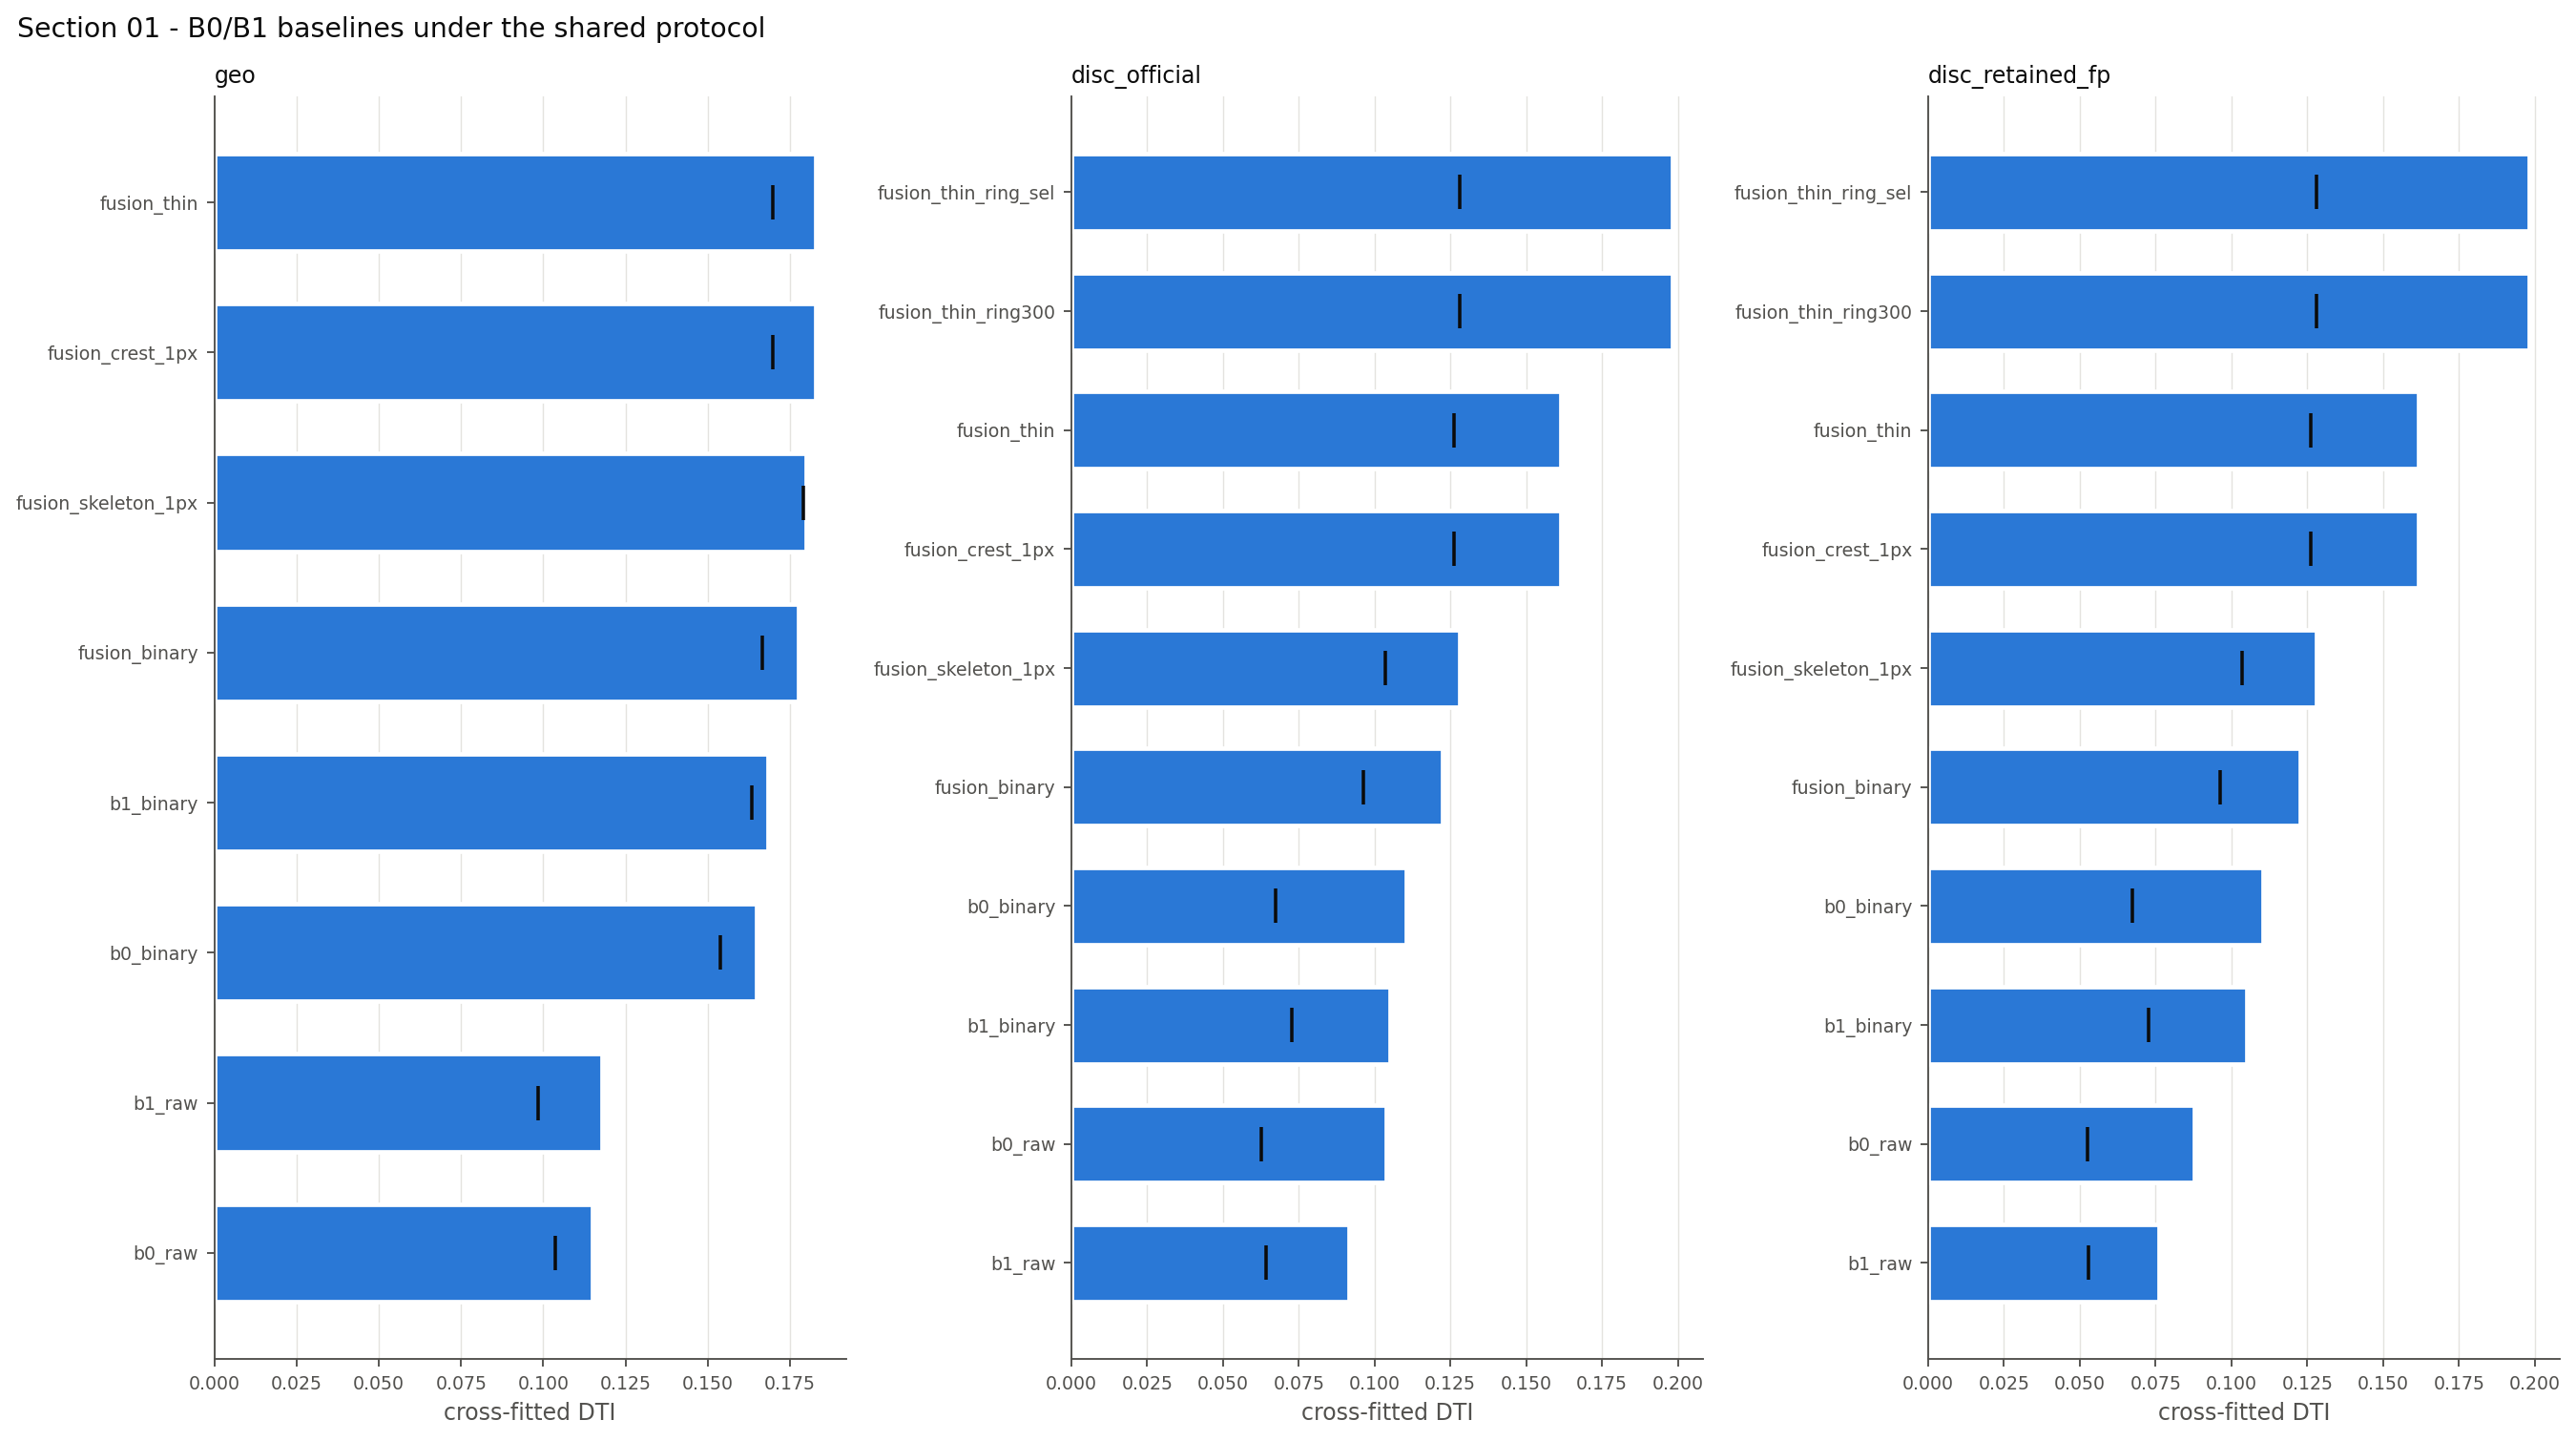

In [5]:
if m9.enabled('s01_baseline'):
    s01 = m9.s01_baseline()
    t = s01['table']
    display(t[[c for c in ('task', 'method', 'dti_crossfit', 'fold_min', 'optimism', 'area_frac_eligible_mean') if c in t]])
    display(s01['recorded'])
    comp = s01['compatibility']
    display(comp)
    if len(comp) and (comp.status == 'DIFFERS').any():
        print('WARNING: compatibility differences:', comp[comp.status == 'DIFFERS'].check.tolist())
    tab('gate0', 'baseline')
    show(['baseline_dti'], 'baseline')

## 02. Feature-store audit and geological representation

* **Research objective.** Turn the ~139 cached features into a compact, non-redundant, provenance-tracked input pyramid; add only the cross-modal evidence that does not exist yet.
* **Geological rationale.** Potential-field gradients, tilt / normalised derivatives, curvature, ridges, directional filters, coherence and terrain morphology express faults differently. Magnetic and gravity maxima need not coincide (different depths, dip, ~2 km gravity resolution), so agreement must be spatially tolerant and never required. Strain / seismicity are regional descriptors, not fault locators: they feed the low-resolution branch only.
* **Inputs.** Feature store (Phase 2 / EDA / Phase 4 / Phase 5), raw bands.
* **Method.** Inventory with family rules; greedy label-free Spearman pruning per family (B0's channels kept first); new layers: tolerant magnetic–gravity alignment (300 / 800 m), tolerant terrain–magnetic alignment (surface / subsurface), tolerant orientation agreement, relative magnetic / gravity strength, localized contrast (LCN). No label is read.
* **Expected artifacts.** `features/inventory.csv` (family, units, resolution, cache state, fingerprint), `selected_registry.csv`, `redundancy_pairs.csv`, `crossmodal_new.csv`, `selected_spearman.csv`, `features/figures/feature_families.png`; layers in `cache/m9/layers`.
* **Validation criteria.** Every selected channel has provenance and a fingerprint; no family exceeds its cap; supervised value is judged only in section 03 (nested).
* **Reload / resume.** Fingerprinted; cached layers are reused (rebuilt only if the cache is lost).

[m9] s02_features: computed in 285s -> /content/gems_work/outputs/m9_geofault_production
[sync out] 18 copied (0.3 MiB), 110 unchanged, 1s: ['outputs/m9_geofault_production']


selected,False,True
family,,
coherence,0,5
crossmodal,14,6
crossmodal_new,0,12
curvature,5,6
directional,13,6
persistence,1,6
potential_gradients,2,6
profiles,32,0
raw,0,14


,name,family,units,note,source_resolution_m,fingerprint
0,m9:xmod:mag_grav_tol@300m_1km,crossmodal_new,dimensionless,geometric mean of magnetic edge rank and the m...,100,de2043af1f133012
1,m9:xmod:mag_grav_tol@800m_1km,crossmodal_new,dimensionless,geometric mean of magnetic edge rank and the m...,100,6fe626653b1e03f9
2,m9:xmod:mag_grav_orient@1km,crossmodal_new,dimensionless,tolerant axial orientation agreement c_m c_g c...,100,81d888610ab3410c
3,m9:xmod:mag_over_grav@1km,crossmodal_new,log ratio,signed log ratio of rank-normalised magnetic /...,100,70fcdaf9ba9dfb71
4,m9:xmod:terr_mag_tol@300m_1km,crossmodal_new,dimensionless,surface / subsurface: terrain edge rank x max ...,100,5285df7596b4ab00
5,m9:xmod:mag_grav_tol@300m_2km,crossmodal_new,dimensionless,geometric mean of magnetic edge rank and the m...,100,8d9bff82a6e72f54
6,m9:xmod:mag_grav_tol@800m_2km,crossmodal_new,dimensionless,geometric mean of magnetic edge rank and the m...,100,cdd9794ba33dd166
7,m9:xmod:mag_grav_orient@2km,crossmodal_new,dimensionless,tolerant axial orientation agreement c_m c_g c...,100,829226e0d6839ccc
8,m9:xmod:mag_over_grav@2km,crossmodal_new,log ratio,signed log ratio of rank-normalised magnetic /...,100,487a1a2827dc5b4c
9,m9:xmod:terr_mag_tol@300m_2km,crossmodal_new,dimensionless,surface / subsurface: terrain edge rank x max ...,100,3db14d7b8a5f7e5a


,a,b,abs_spearman
0,rs:terrain:tri@0.1km,raw:det_elev_slope,0.976410
1,rs:terrain:tri@0.3km,raw:det_elev_slope,0.932441
2,terrain:thdr@1km,terrain:thdr@0.5km,0.962055
3,terrain:std@1km,terrain:thdr@0.5km,0.965931
4,rs:terrain:range@1km,terrain:thdr@0.5km,0.967527
5,rs:terrain:range@2km,terrain:thdr@0.5km,0.940340
6,gravity:thdr@2km,raw:iso_grav_anom_slope,0.979003


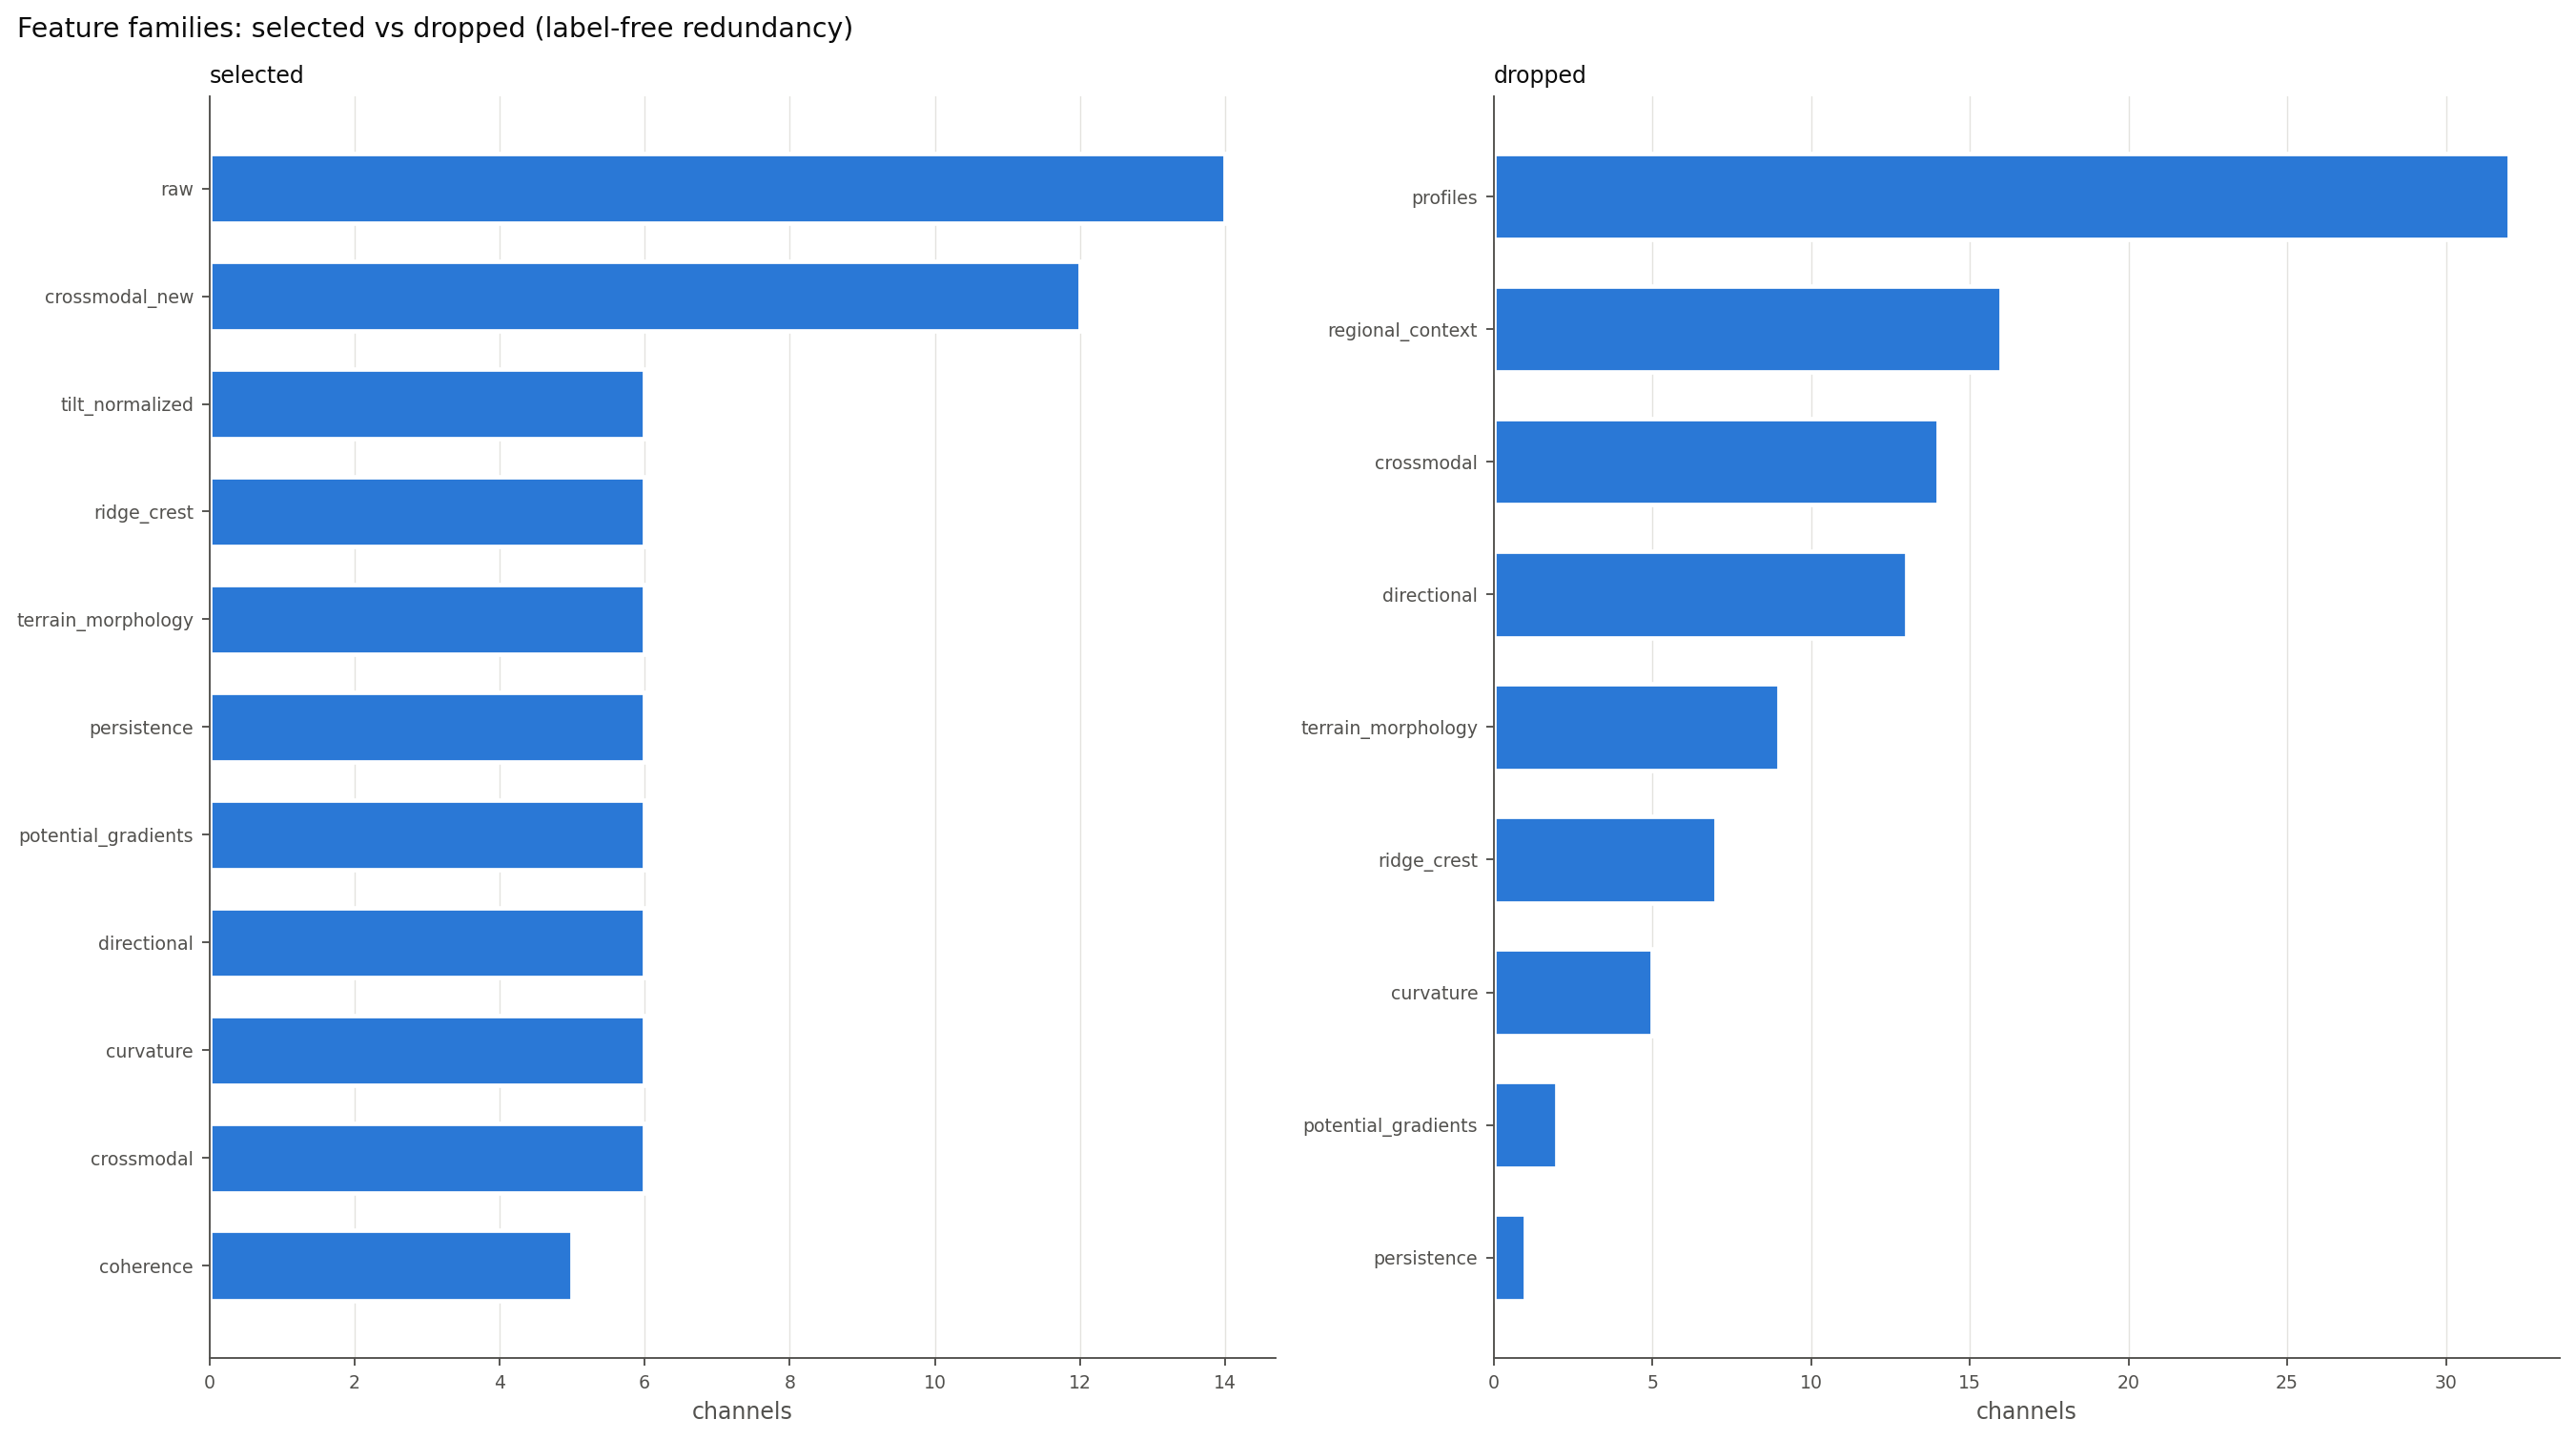

In [6]:
if m9.enabled('s02_features'):
    s02 = m9.s02_features()
    reg = s02['registry']
    display(reg.groupby(['family', 'selected']).size().rename('n').unstack(fill_value=0))
    tab('crossmodal_new', 'features')
    tab('redundancy_pairs', 'features', 20)
    show(['feature_families'], 'features/figures')

## 03. Fourier / wavelet feature pipeline — Gate 1

* **Research objective.** Extract structural frequency, orientation and multiscale information not already represented, and decide (nested) whether it — and the new cross-modal layers — earn a place in the production inputs.
* **Geological rationale.** A linear structure concentrates spectral energy along the wavevector *perpendicular* to its trace (trace strike = wavevector azimuth + 90°). Anisotropy, directional coherence and scale persistence describe fabric that single-scale gradients miss. Upward continuation is the stable physical scale-space of a potential field; downward continuation is unstable and is not used. Spectral slopes are not interpreted as depths.
* **Inputs.** Magnetic (`rtp`) and gravity (`iso_grav_anom`) fields.
* **Method.** Overlapping 6.4 km windows (Hann taper, plane removal, nodata-aware) → anisotropy, dominant strike (doubled angle), directional entropy, short / long energy ratio, radial slope, band energy; steerable one-sided log-Gabor wavelets at 0.4–3.2 km → energy per scale, orientation, coherence, persistence, fine / coarse ratio; continuation bands; optional STFT ablation. Label-free pruning and comparison with existing Gabor / ridge / DoG features. **Gate 1** evidence: pixel LightGBM screen trained on each trained zone's TRAINING geography only, scored on its held-out zone with the official scorer (`raw`, `base`, `base_no_new`, `base_spectral`), unique systems, nested consistency.
* **Expected artifacts.** `spectral/spectral_registry.csv`, `spectral_vs_existing.csv`, `fft_windows_<field>.npz`, `screen_per_zone.csv`, `screen_pooled.csv`, `screen_unique_systems.csv`, `screen_nested_consistency.csv`, `gate1.csv`; figures `fourier_*`, `wavelet_*`, `mag_grav_agreement`, `feature_set_comparison`, `raw_vs_structural`.
* **Validation criteria.** Gate 1 INCLUDE a component when its pooled DTI gain ≥ 0.003 or it recovers ≥ 2 systems the base set misses; otherwise EXCLUDE (kept for diagnostics). The `no_spectral` network variant (FULL) confirms the decision at network level (section 09 `variant_deltas`).
* **Reload / resume.** Layers cached in `cache/m9/layers`; the stage is fingerprinted.

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ut

[m9] s02 screen geo:0 raw: dti=0.1382 auc_pr=0.0238


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ut

[m9] s02 screen geo:0 base: dti=0.1808 auc_pr=0.0368


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ut

...

,name,family,kind,field,note,fingerprint,selected,reason
0,m9:spec:magnetic_fft_anisotropy,spectral,fft,rtp,windowed FFT (64 px / stride 16),5519a4a5fea9f83d,True,kept
1,m9:spec:magnetic_fft_strike_c2,spectral,fft,rtp,windowed FFT (64 px / stride 16),0dabc7ae35963b84,True,kept
2,m9:spec:magnetic_fft_strike_s2,spectral,fft,rtp,windowed FFT (64 px / stride 16),bf7a43e82ec1143b,True,kept
3,m9:spec:magnetic_fft_dir_entropy,spectral,fft,rtp,windowed FFT (64 px / stride 16),5ffa32bf07015c09,True,kept
4,m9:spec:magnetic_fft_short_long,spectral,fft,rtp,windowed FFT (64 px / stride 16),baf8c1177291d93c,True,kept
5,m9:spec:magnetic_fft_radial_slope,spectral,fft,rtp,windowed FFT (64 px / stride 16),f0d1268e41e0b253,True,kept
6,m9:spec:magnetic_fft_log_energy,spectral,fft,rtp,windowed FFT (64 px / stride 16),7fba35c8073a04dc,True,kept
7,m9:spec:magnetic_wav_energy@0.4km,spectral,wavelet,rtp,log-Gabor steerable wavelet,0e904b5d076e8c27,True,kept
8,m9:spec:magnetic_wav_coherence@0.4km,spectral,wavelet,rtp,log-Gabor steerable wavelet,2d02f06334f13094,True,kept
9,m9:spec:magnetic_wav_strike_c2@0.4km,spectral,wavelet,rtp,log-Gabor steerable wavelet,c13a0a57a2be7076,True,kept


,a,b,spearman,abs_spearman
114,m9:spec:magnetic_wav_energy@3.2km,magnetic:log_gabor@2km,0.963400,0.963400
284,m9:spec:gravity_wav_energy@3.2km,gravity:log_gabor@2km,0.919570,0.919570
90,m9:spec:magnetic_wav_energy@1.6km,magnetic:log_gabor@2km,0.862082,0.862082
206,m9:spec:gravity_fft_log_energy,gravity:log_gabor@2km,0.849357,0.849357
36,m9:spec:magnetic_fft_log_energy,magnetic:log_gabor@2km,0.810438,0.810438
160,m9:spec:magnetic_resid_0.5km,rs:magnetic:dog@1km,0.804556,0.804556
166,m9:spec:magnetic_band_0.5_2km,rs:magnetic:dog@1km,0.793510,0.793510
66,m9:spec:magnetic_wav_energy@0.8km,magnetic:log_gabor@2km,0.773549,0.773549
260,m9:spec:gravity_wav_energy@1.6km,gravity:log_gabor@2km,0.761396,0.761396
236,m9:spec:gravity_wav_energy@0.8km,gravity:log_gabor@2km,0.735065,0.735065


,task,feature_set,dti_pooled,worst_zone_dti,auc_pr_mean,system_recall,n_features,n_zones
0,disc_official,base,0.089891,0.054995,0.012668,0.127990,79.0,3.0
1,disc_official,base_no_new,0.088642,0.053225,0.012166,0.119219,67.0,3.0
2,disc_official,base_spectral,0.089021,0.051490,0.013353,0.119219,91.0,3.0
3,disc_official,raw,0.056605,0.029457,0.007779,0.049043,14.0,3.0
4,geo,base,0.149054,0.124933,0.032079,0.113320,79.0,3.0
5,geo,base_no_new,0.153089,0.128297,0.033169,0.128865,67.0,3.0
6,geo,base_spectral,0.156123,0.128174,0.033755,0.129203,91.0,3.0
7,geo,raw,0.102006,0.078183,0.021021,0.092936,14.0,3.0


,task,unique_systems,set_a,set_b
0,disc_official,2,base_spectral,base
1,geo,18,base_spectral,base
2,disc_official,3,base,base_no_new
3,geo,5,base,base_no_new


,gate,component,task,decision,conditional_dti_gain,unique_systems,zones_agreeing,n_zones,profile,provisional,rule
0,G1_representation,spectral,disc_official,INCLUDE,-0.000870,2,4,6,FULL,False,pooled DTI gain >= 0.003 OR >= 2 systems recov...
1,G1_representation,crossmodal_new,disc_official,INCLUDE,0.001249,3,5,6,FULL,False,pooled DTI gain >= 0.003 OR >= 2 systems recov...


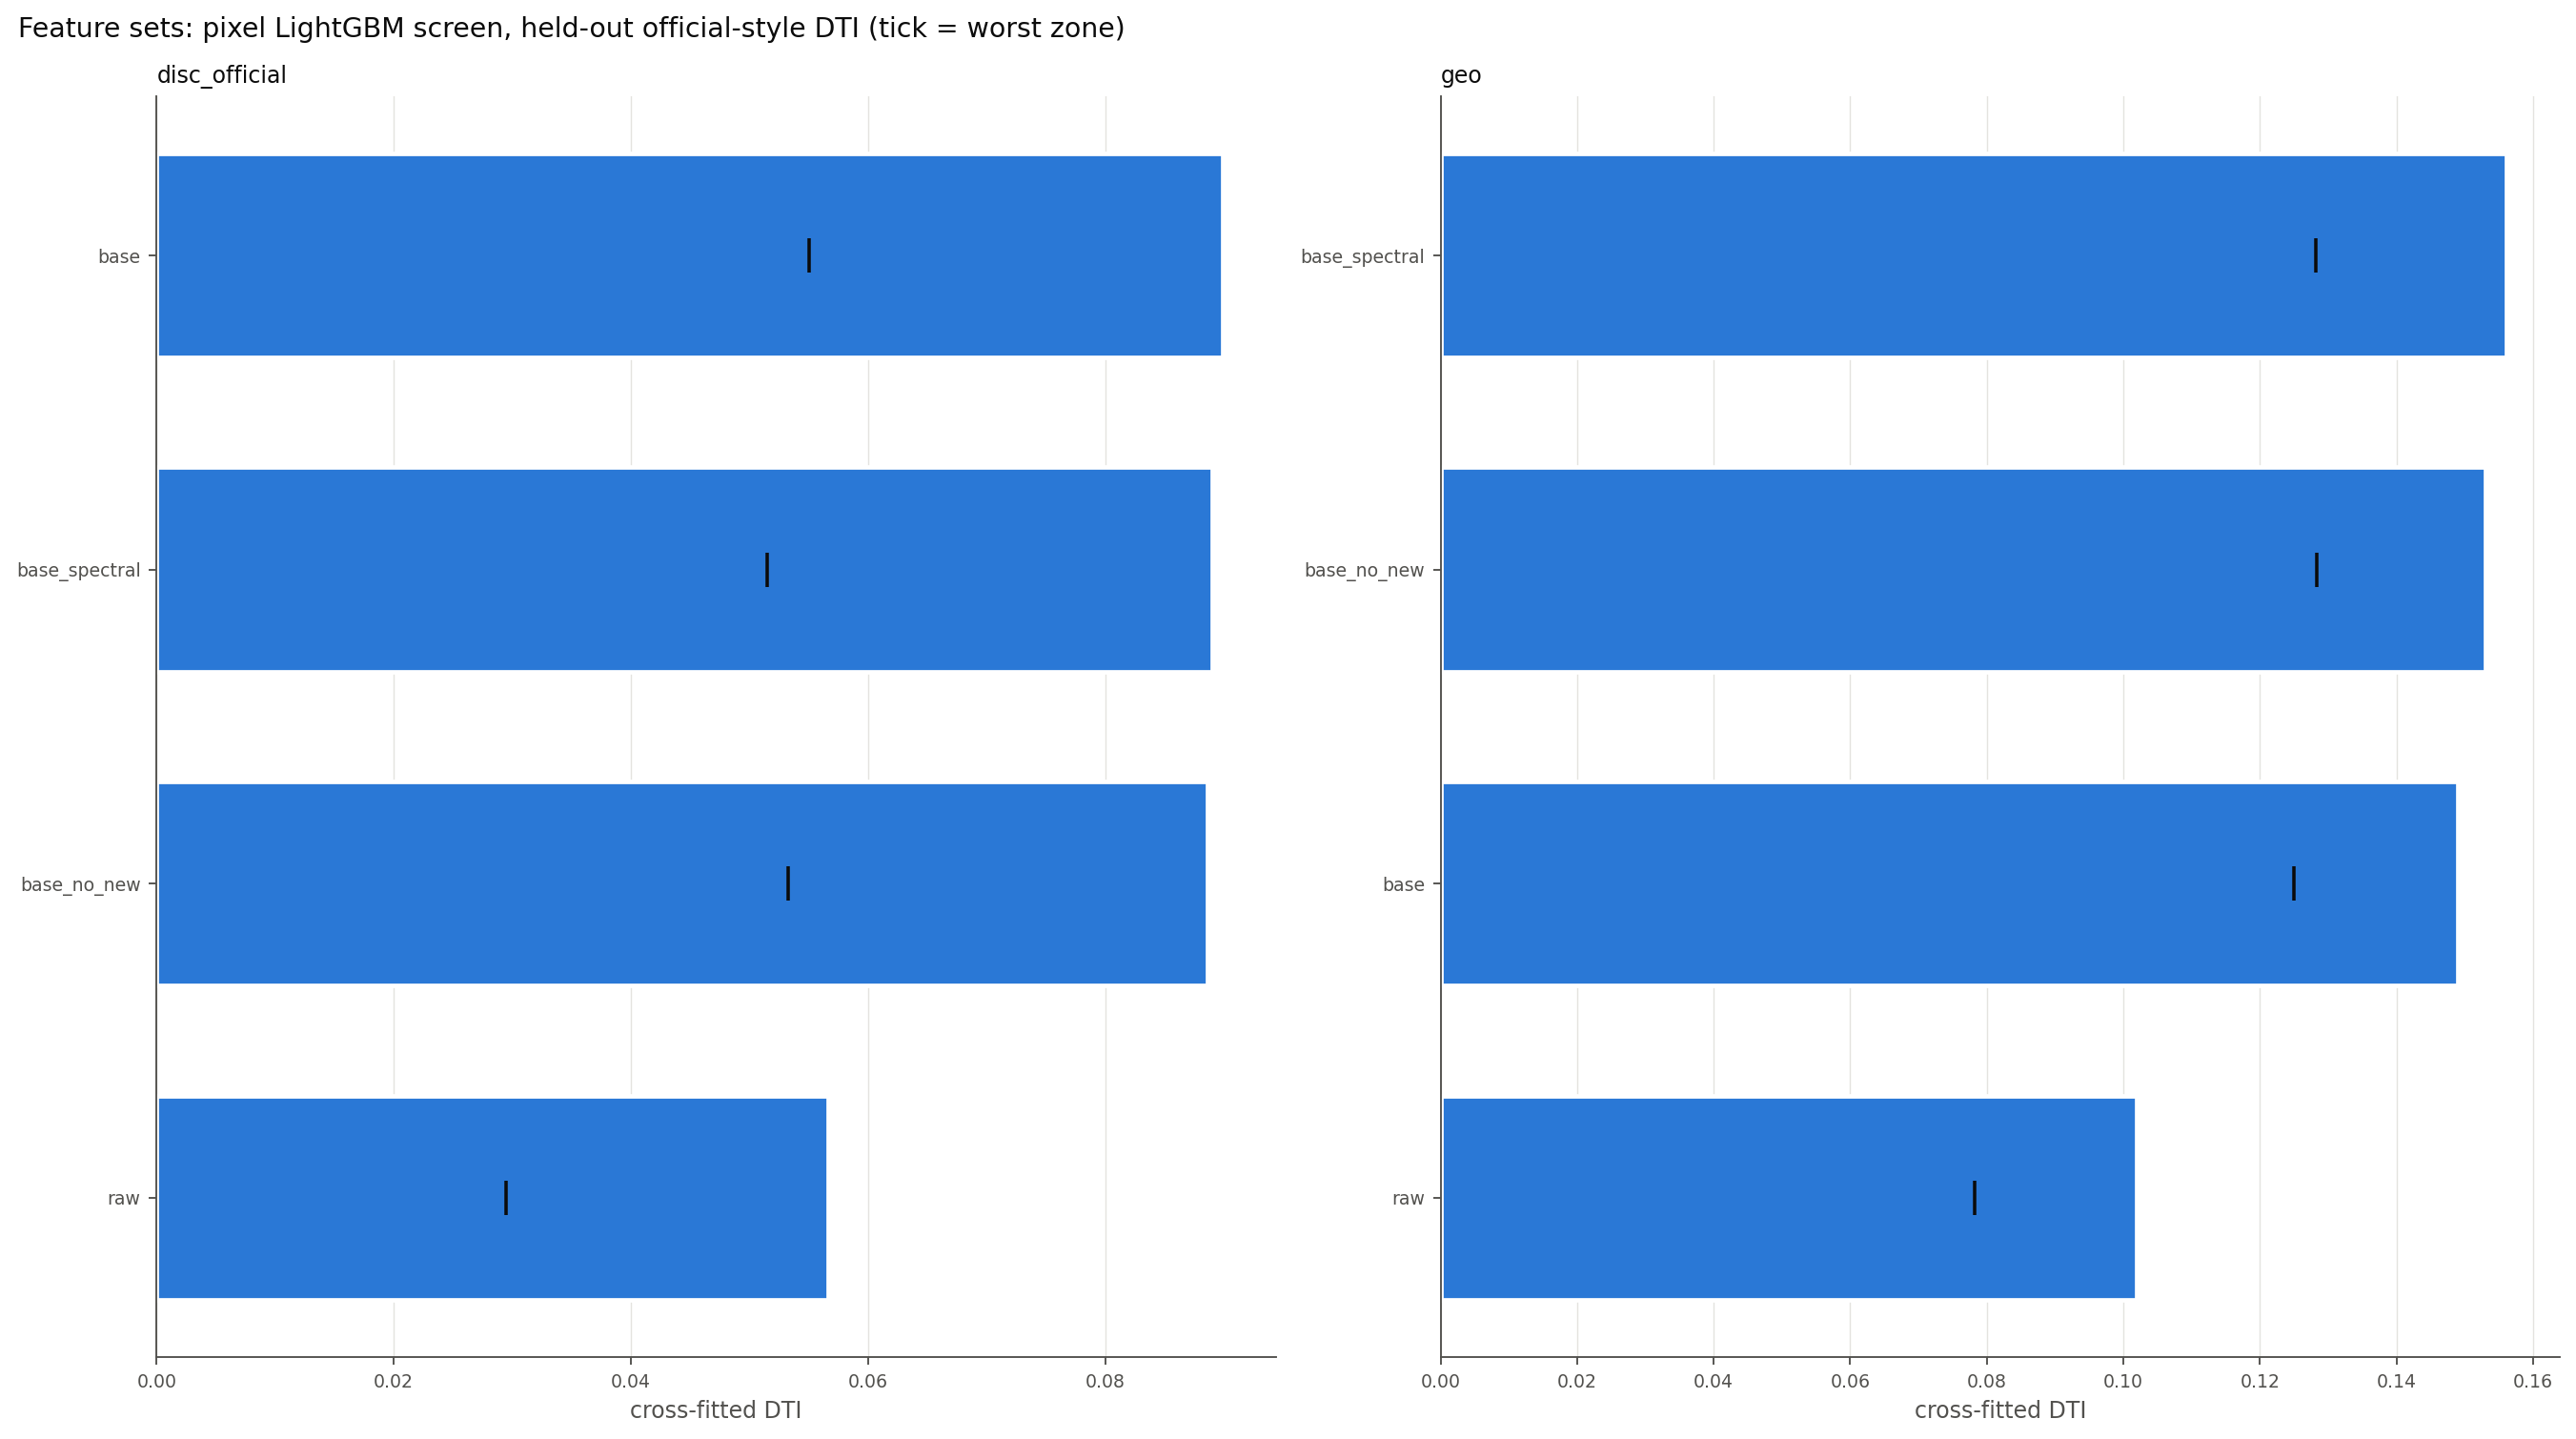

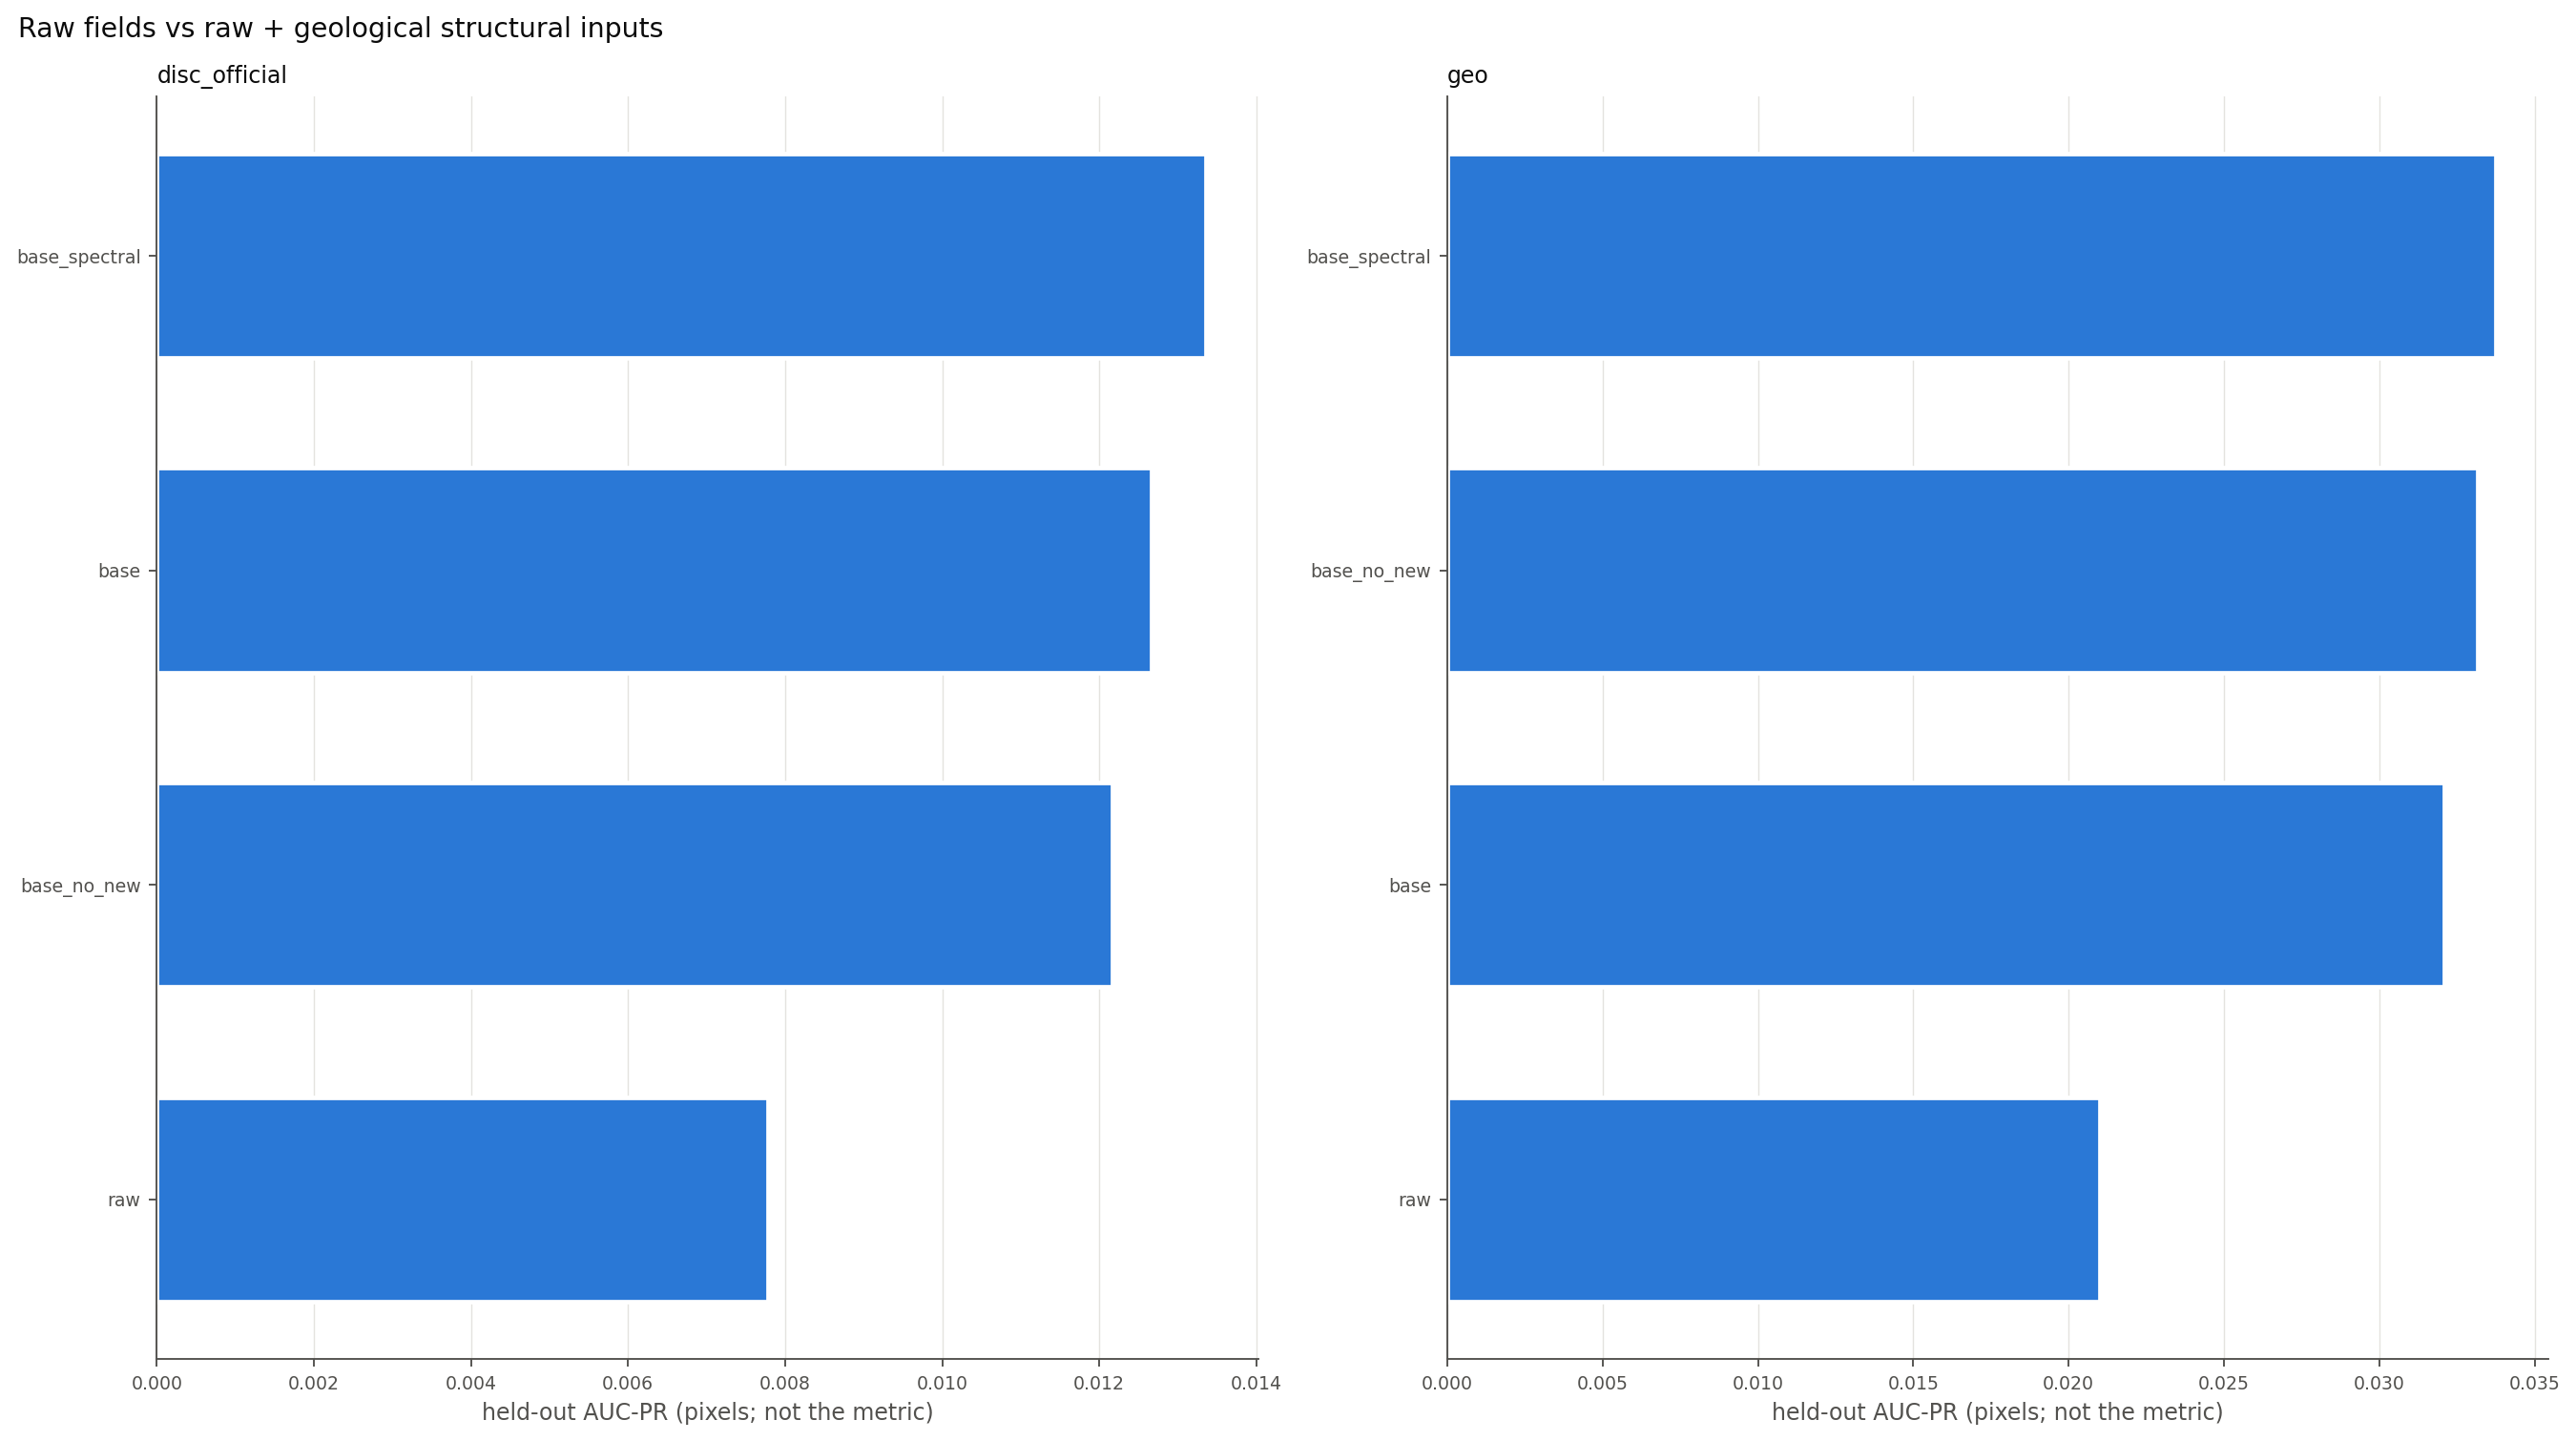

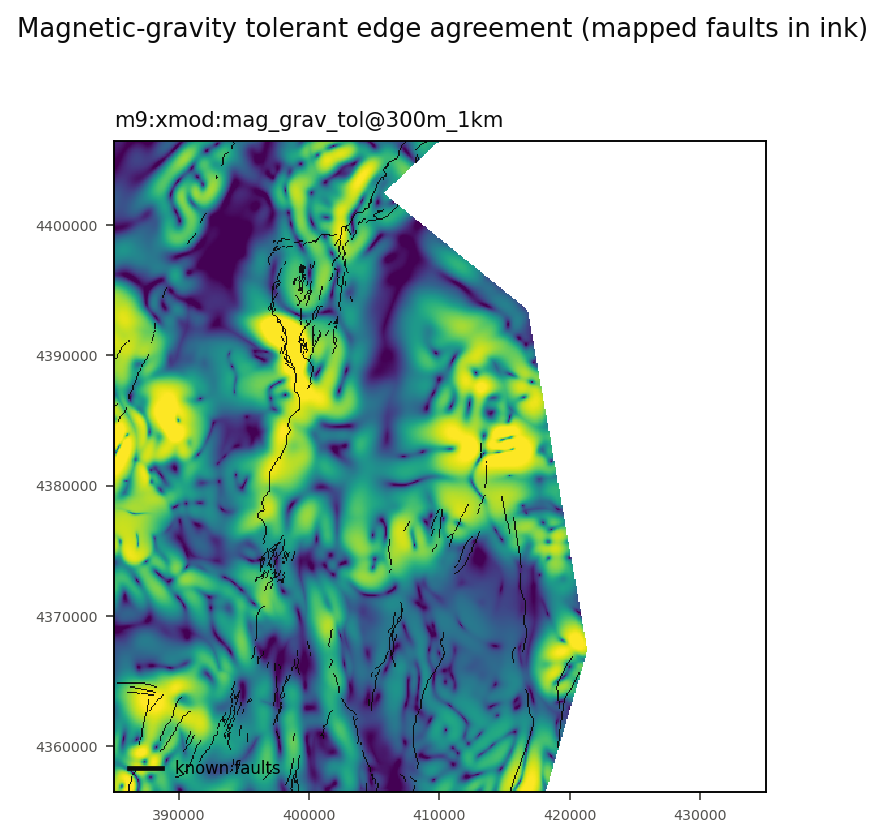

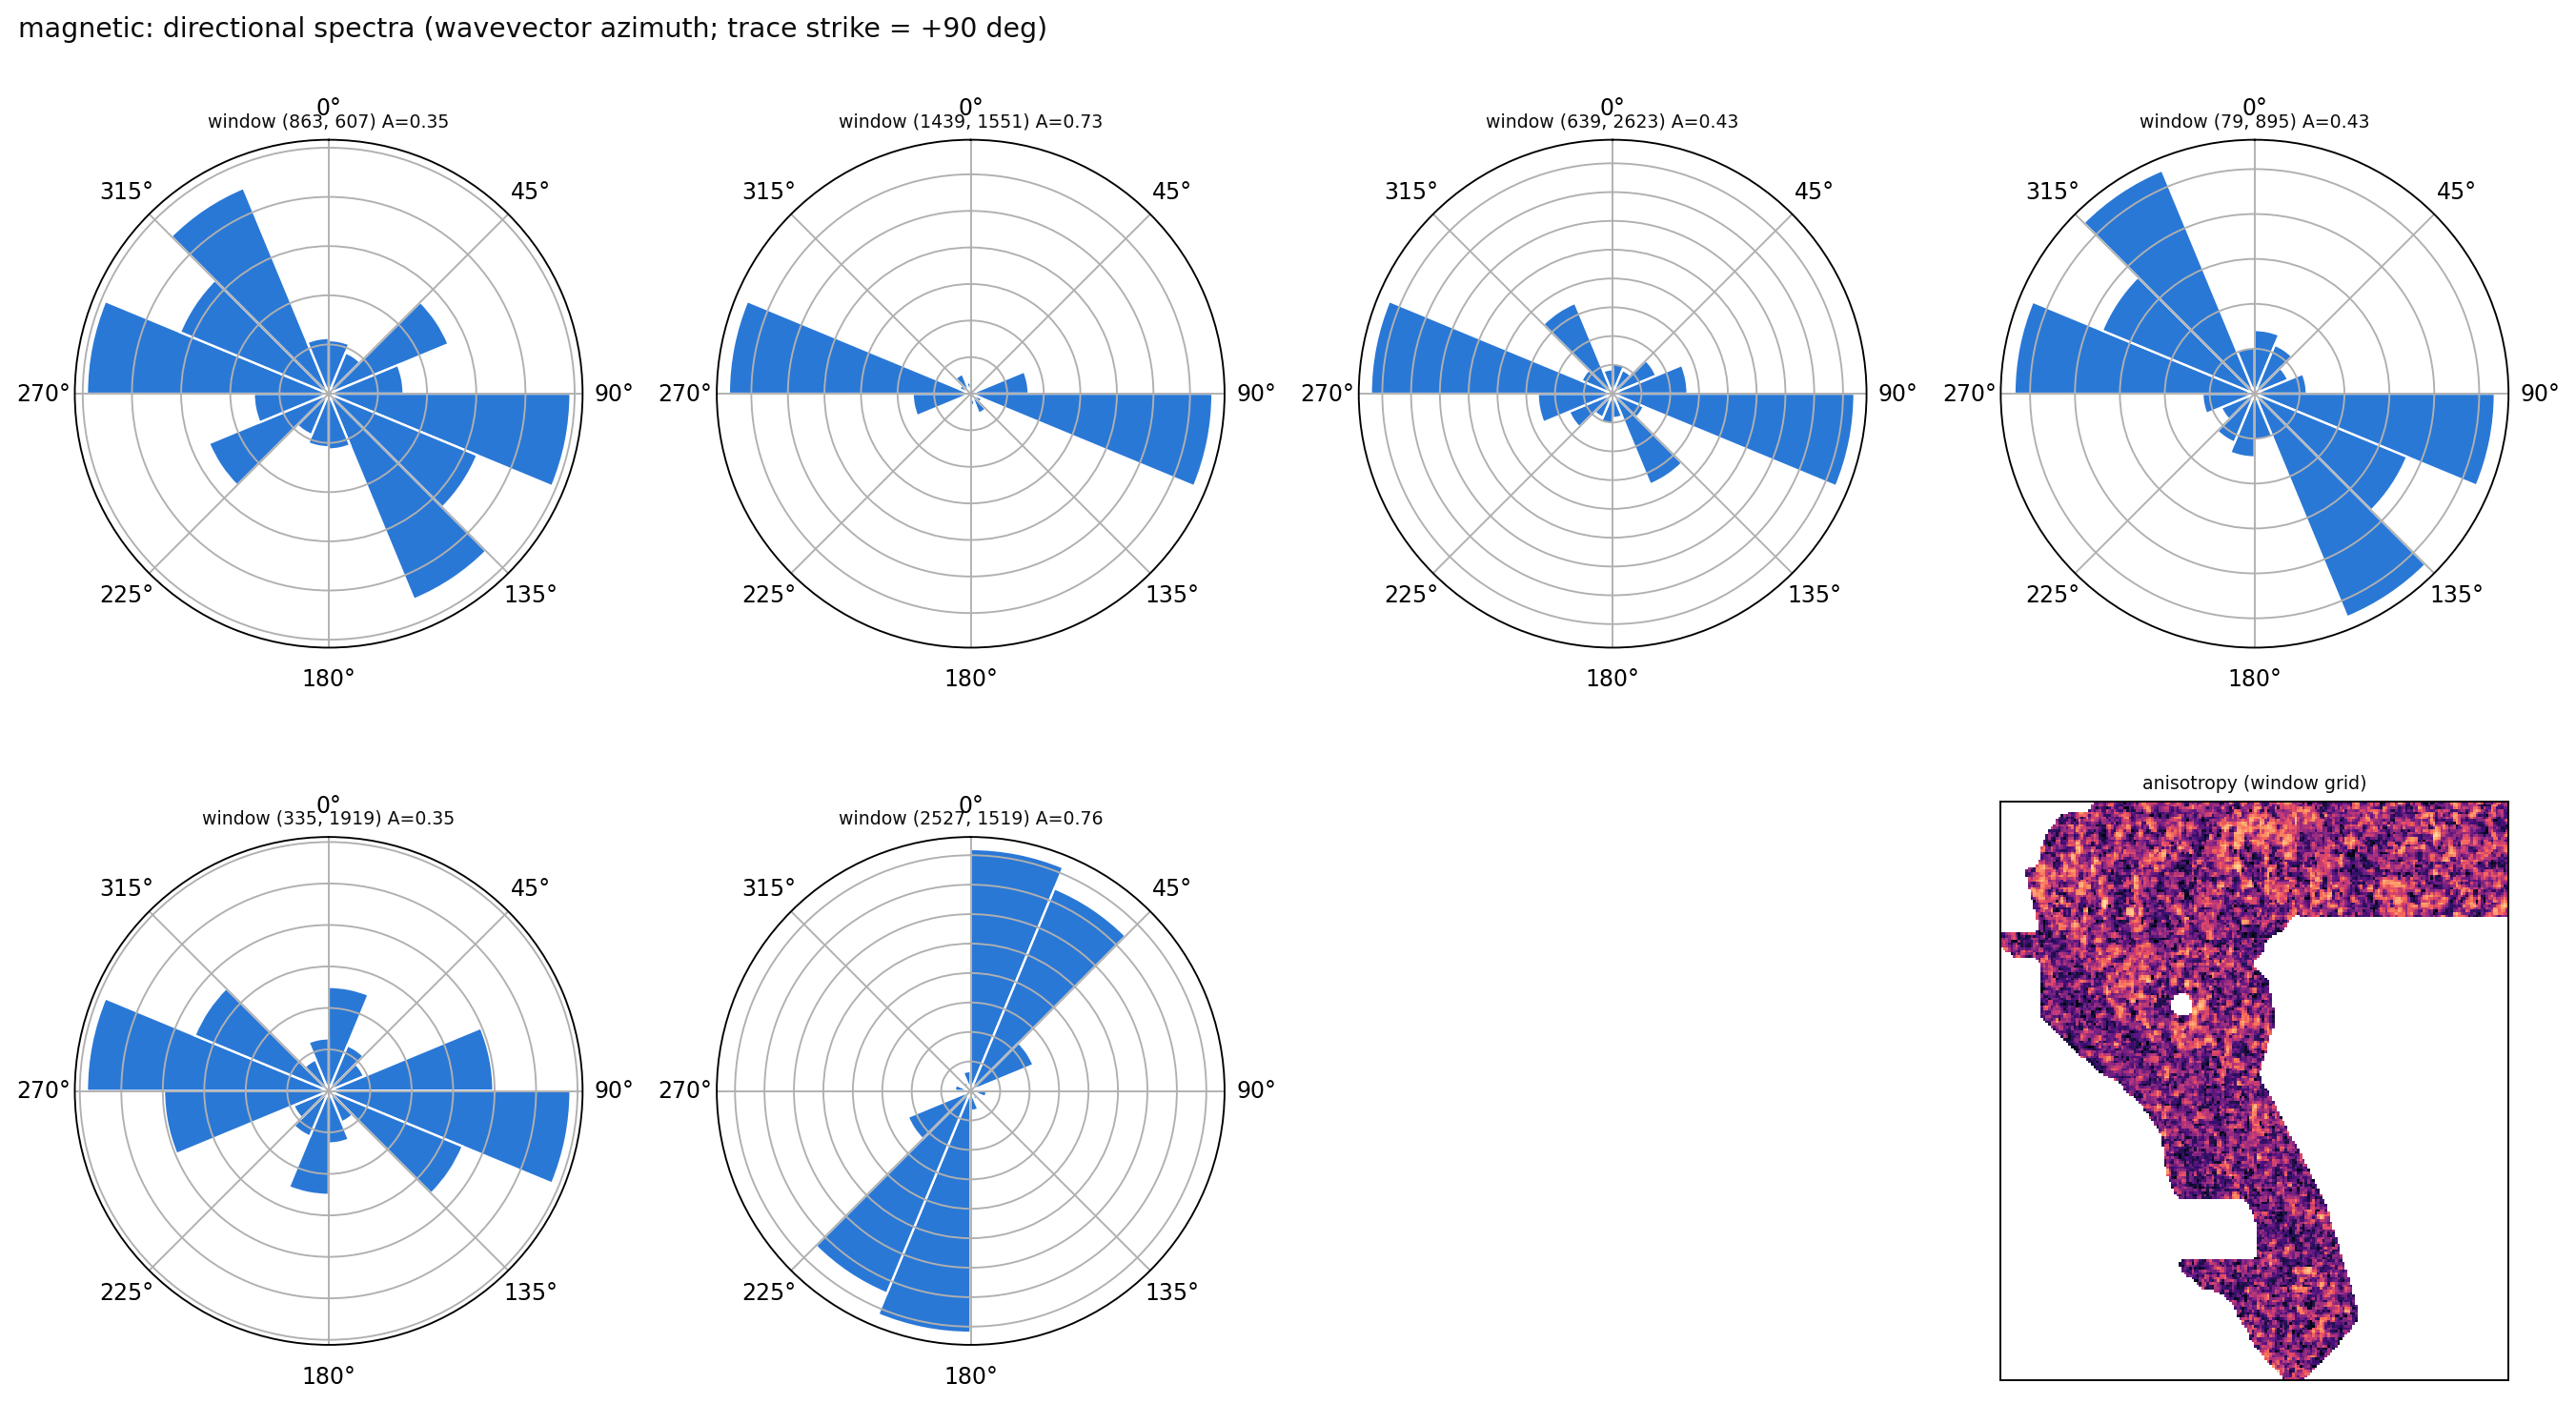

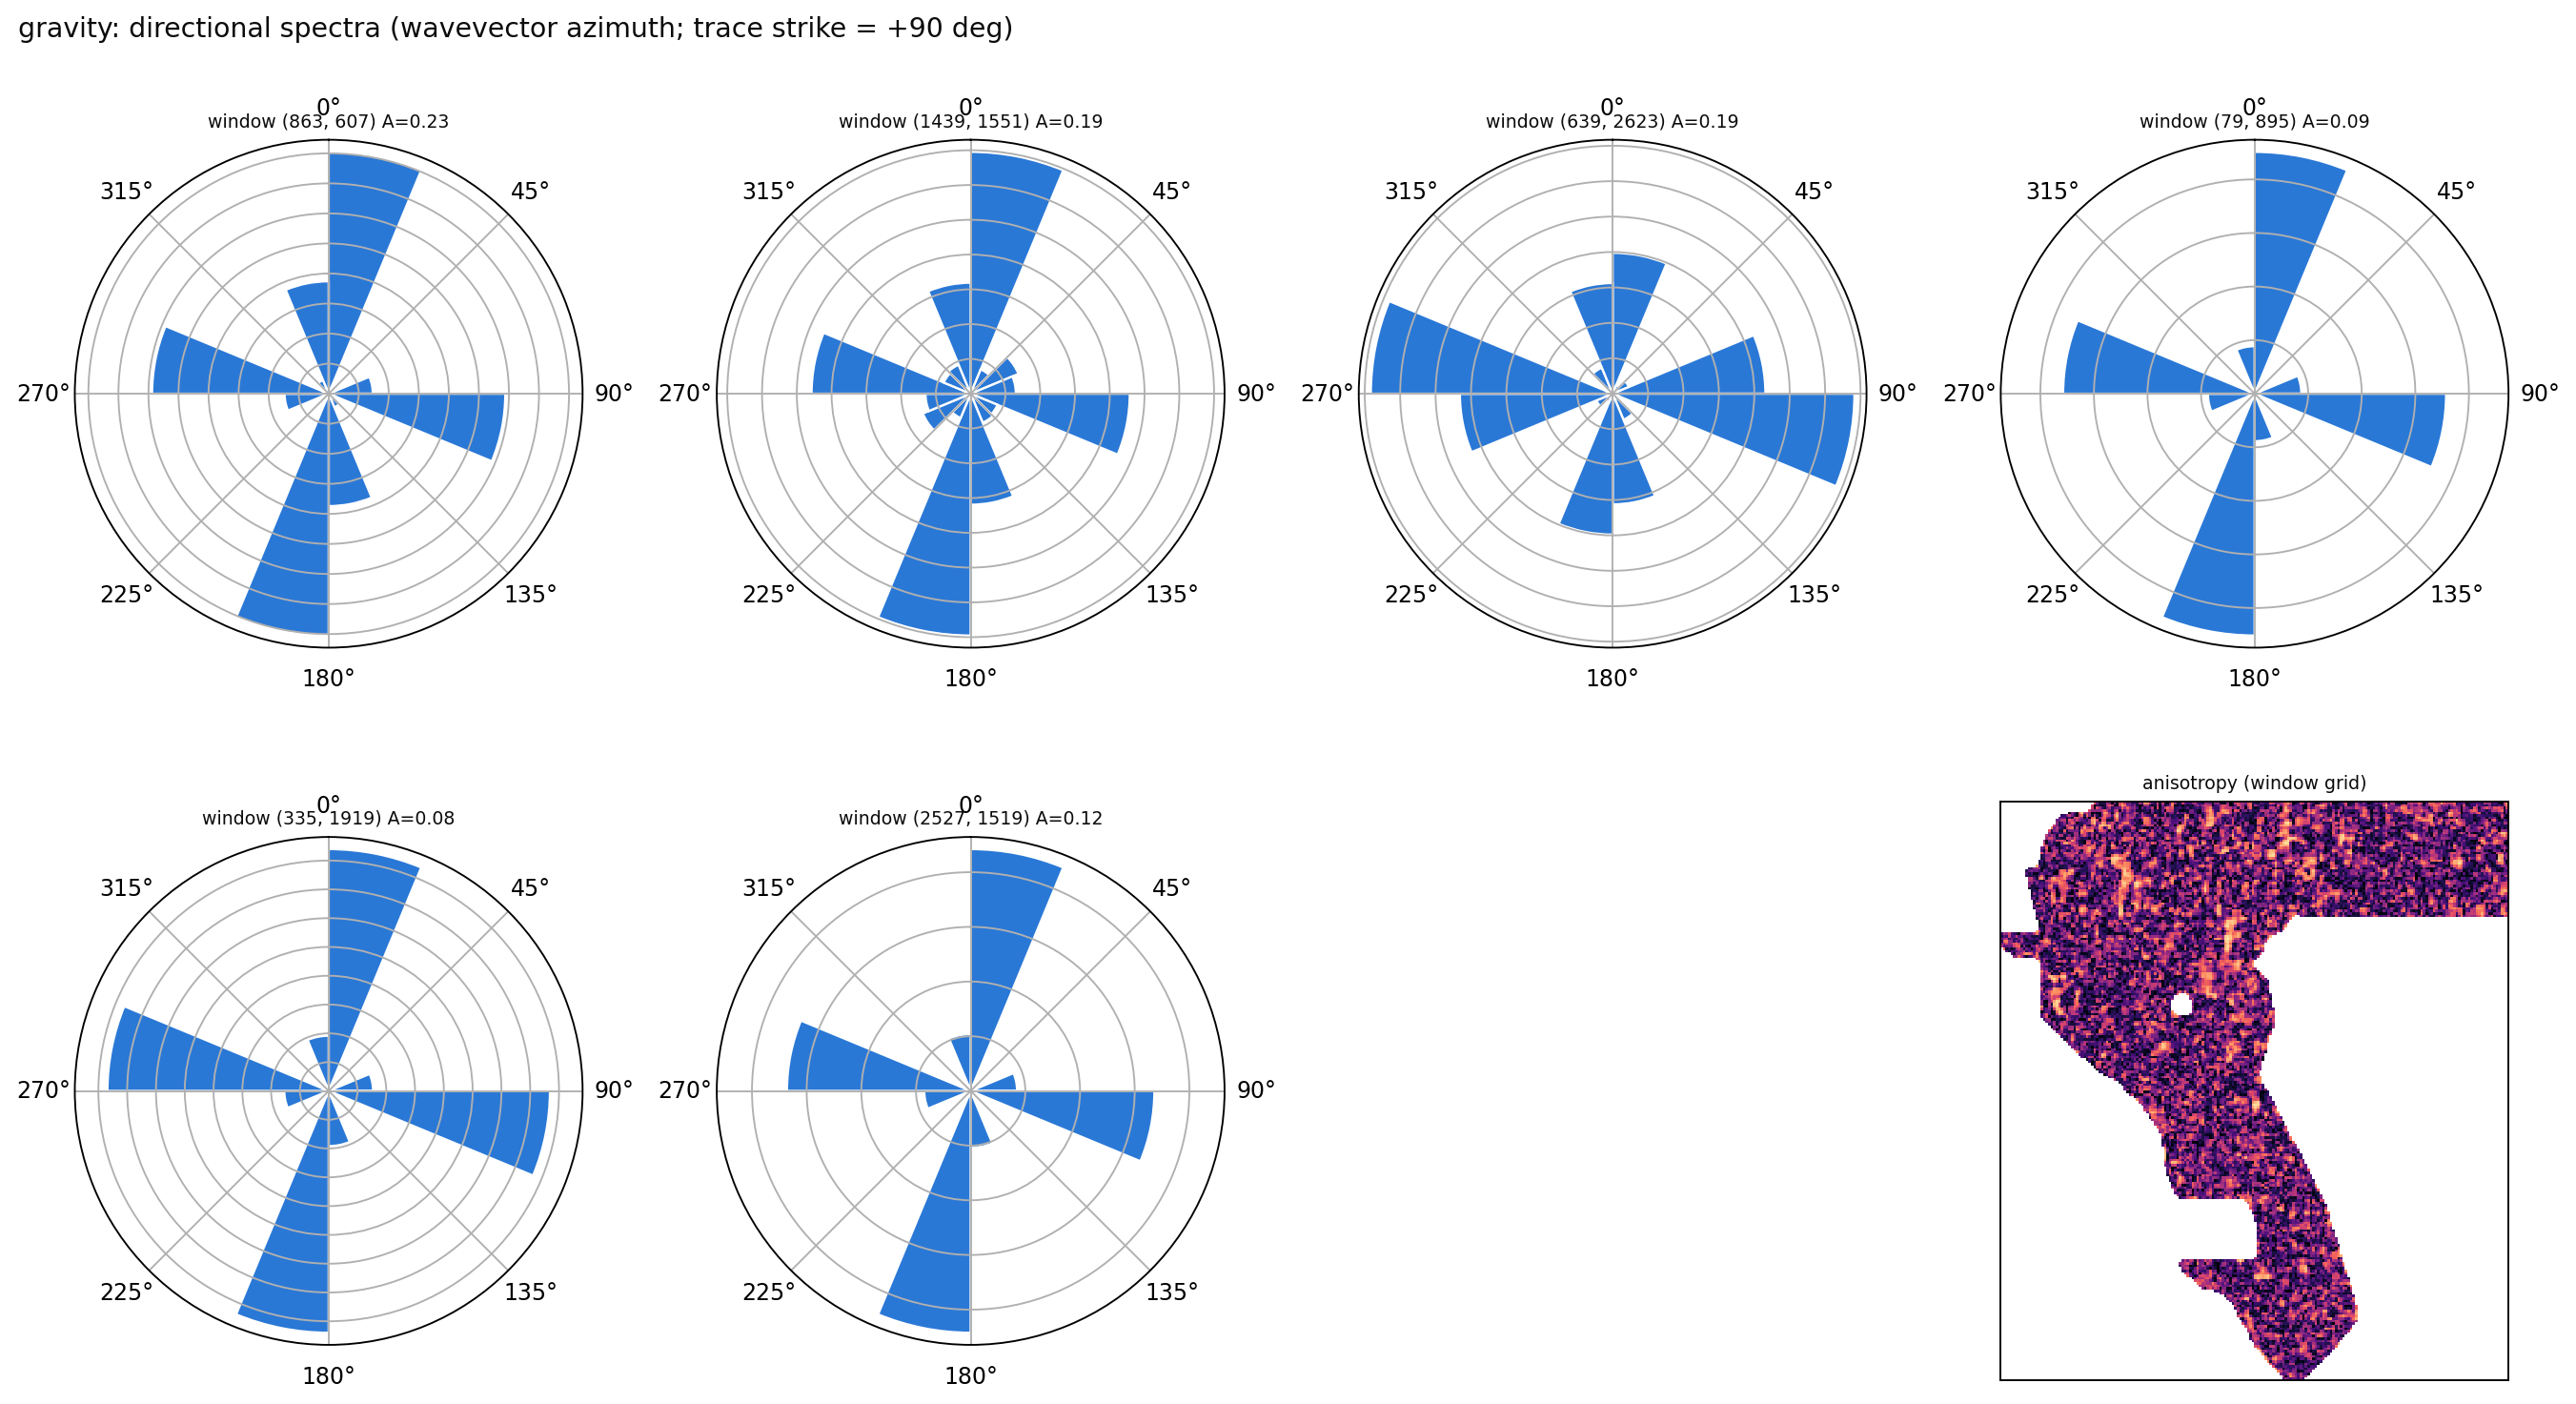

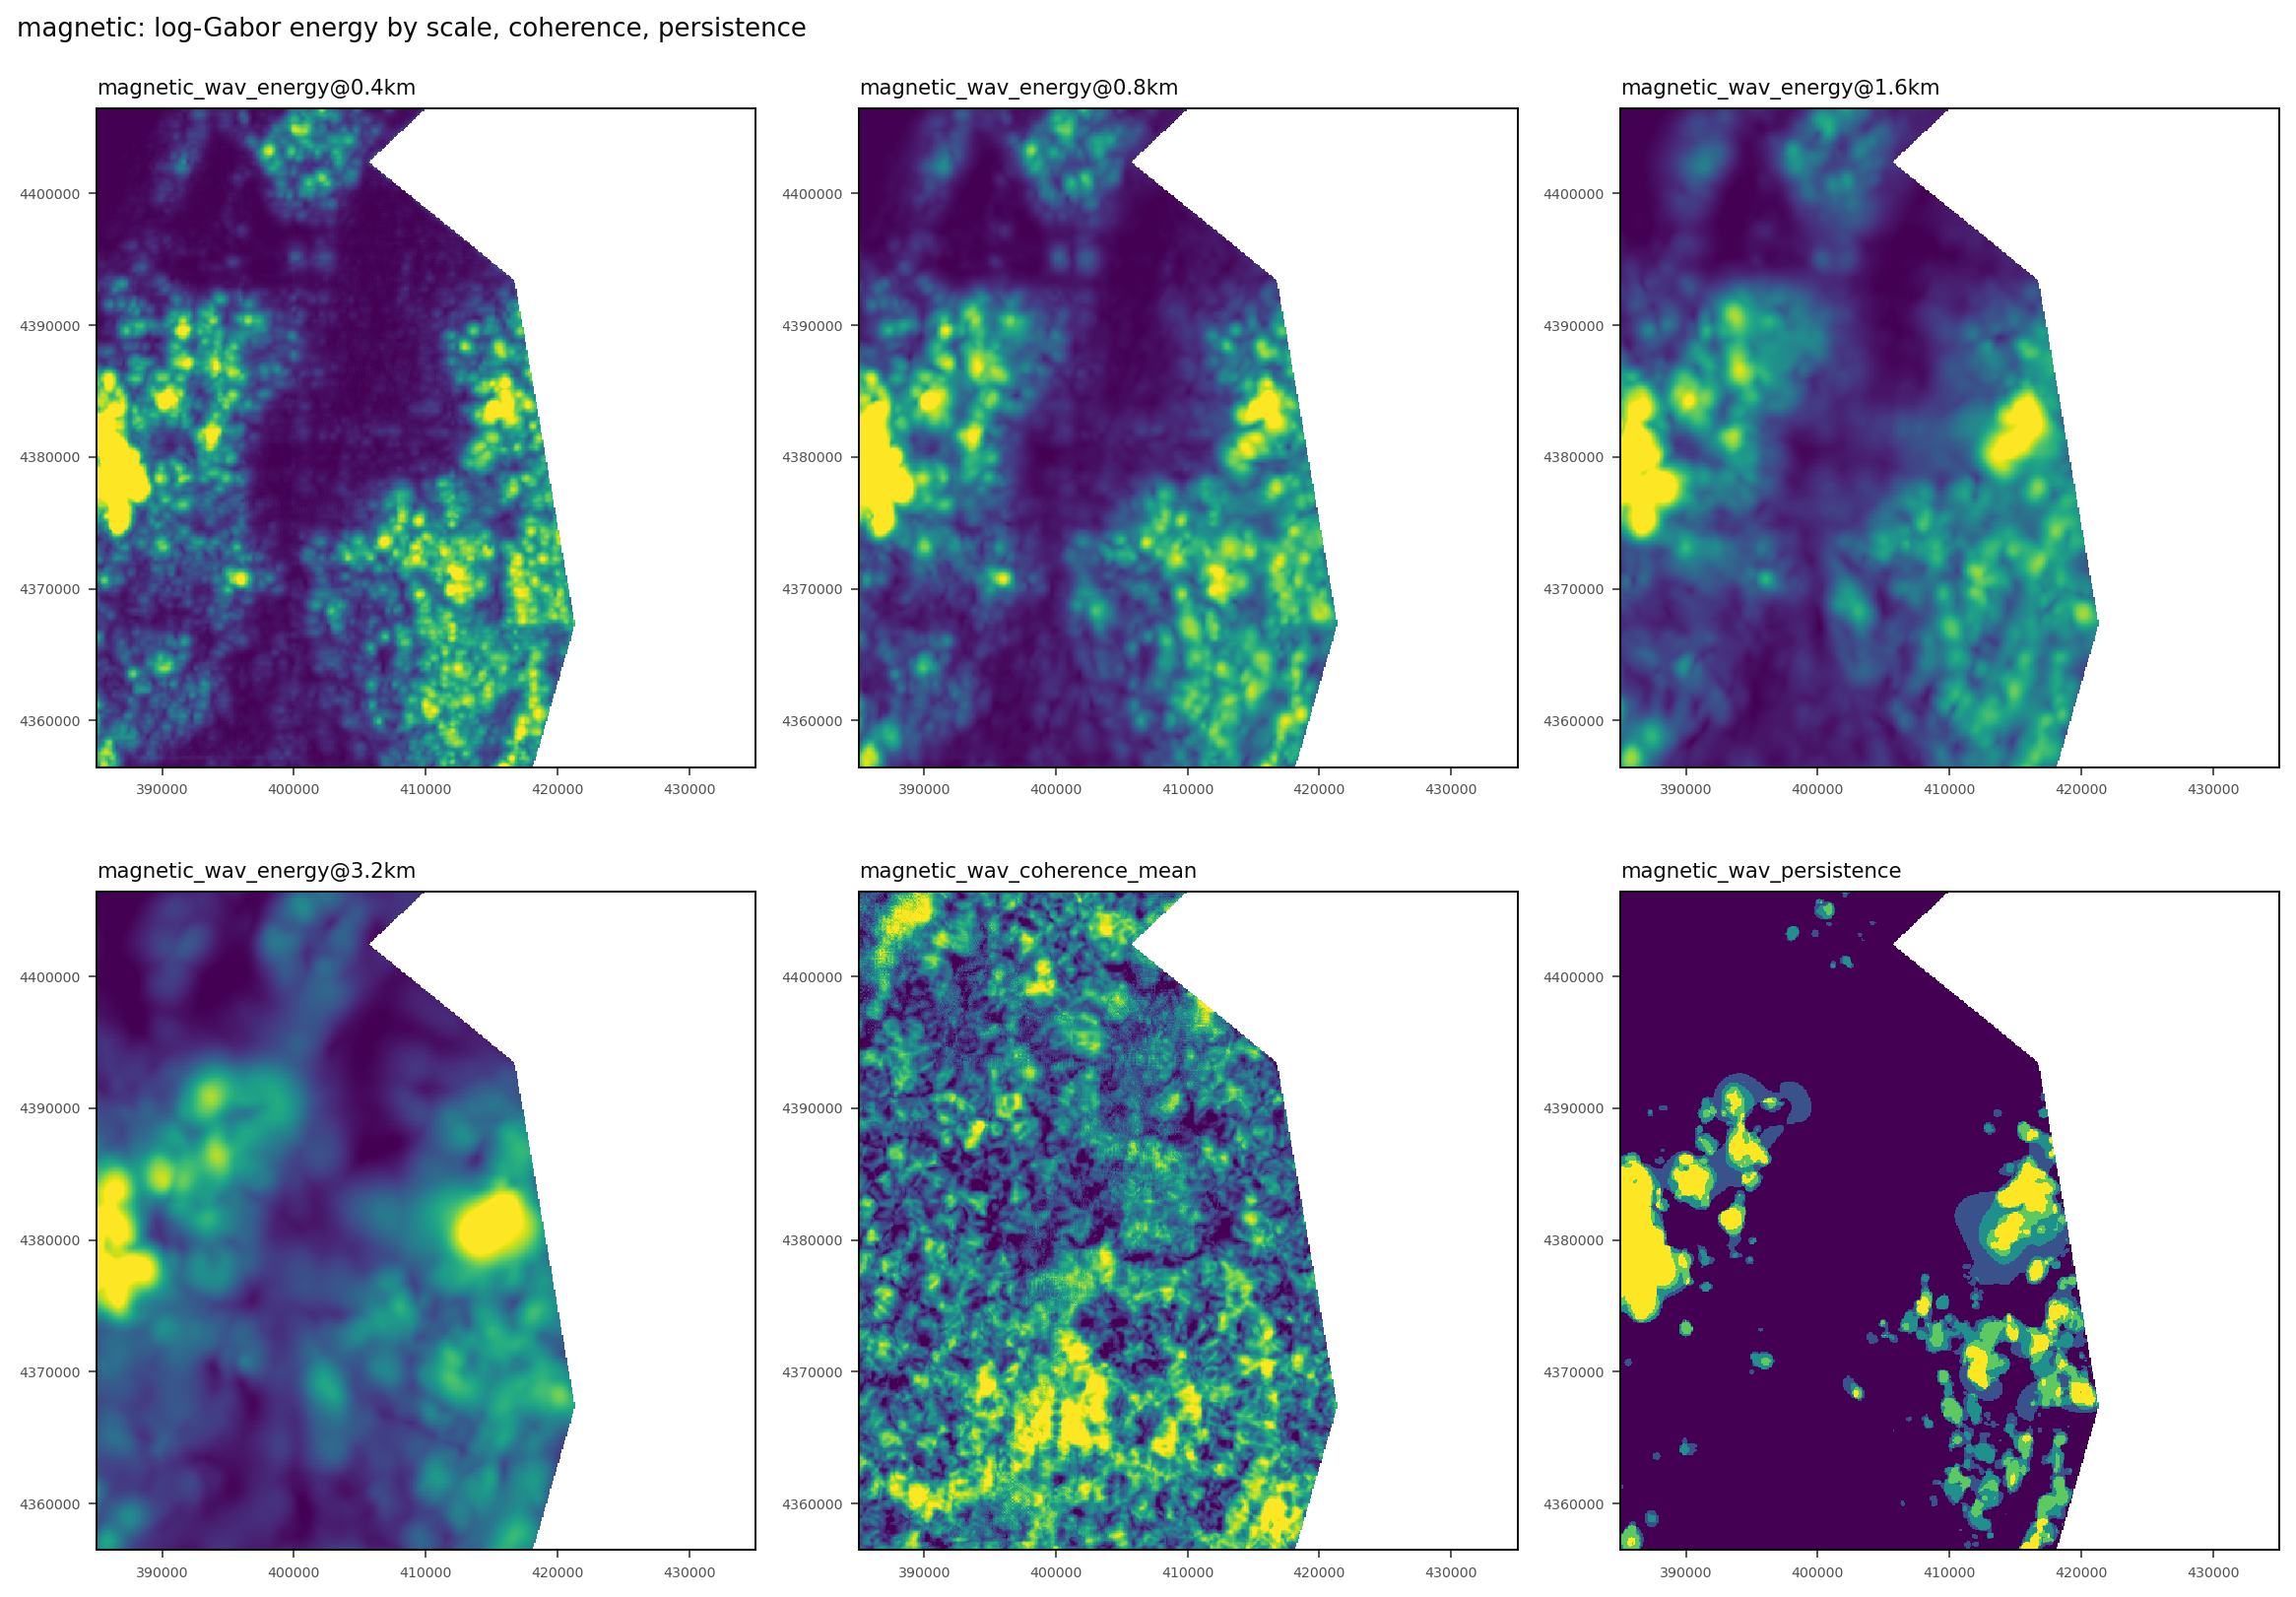

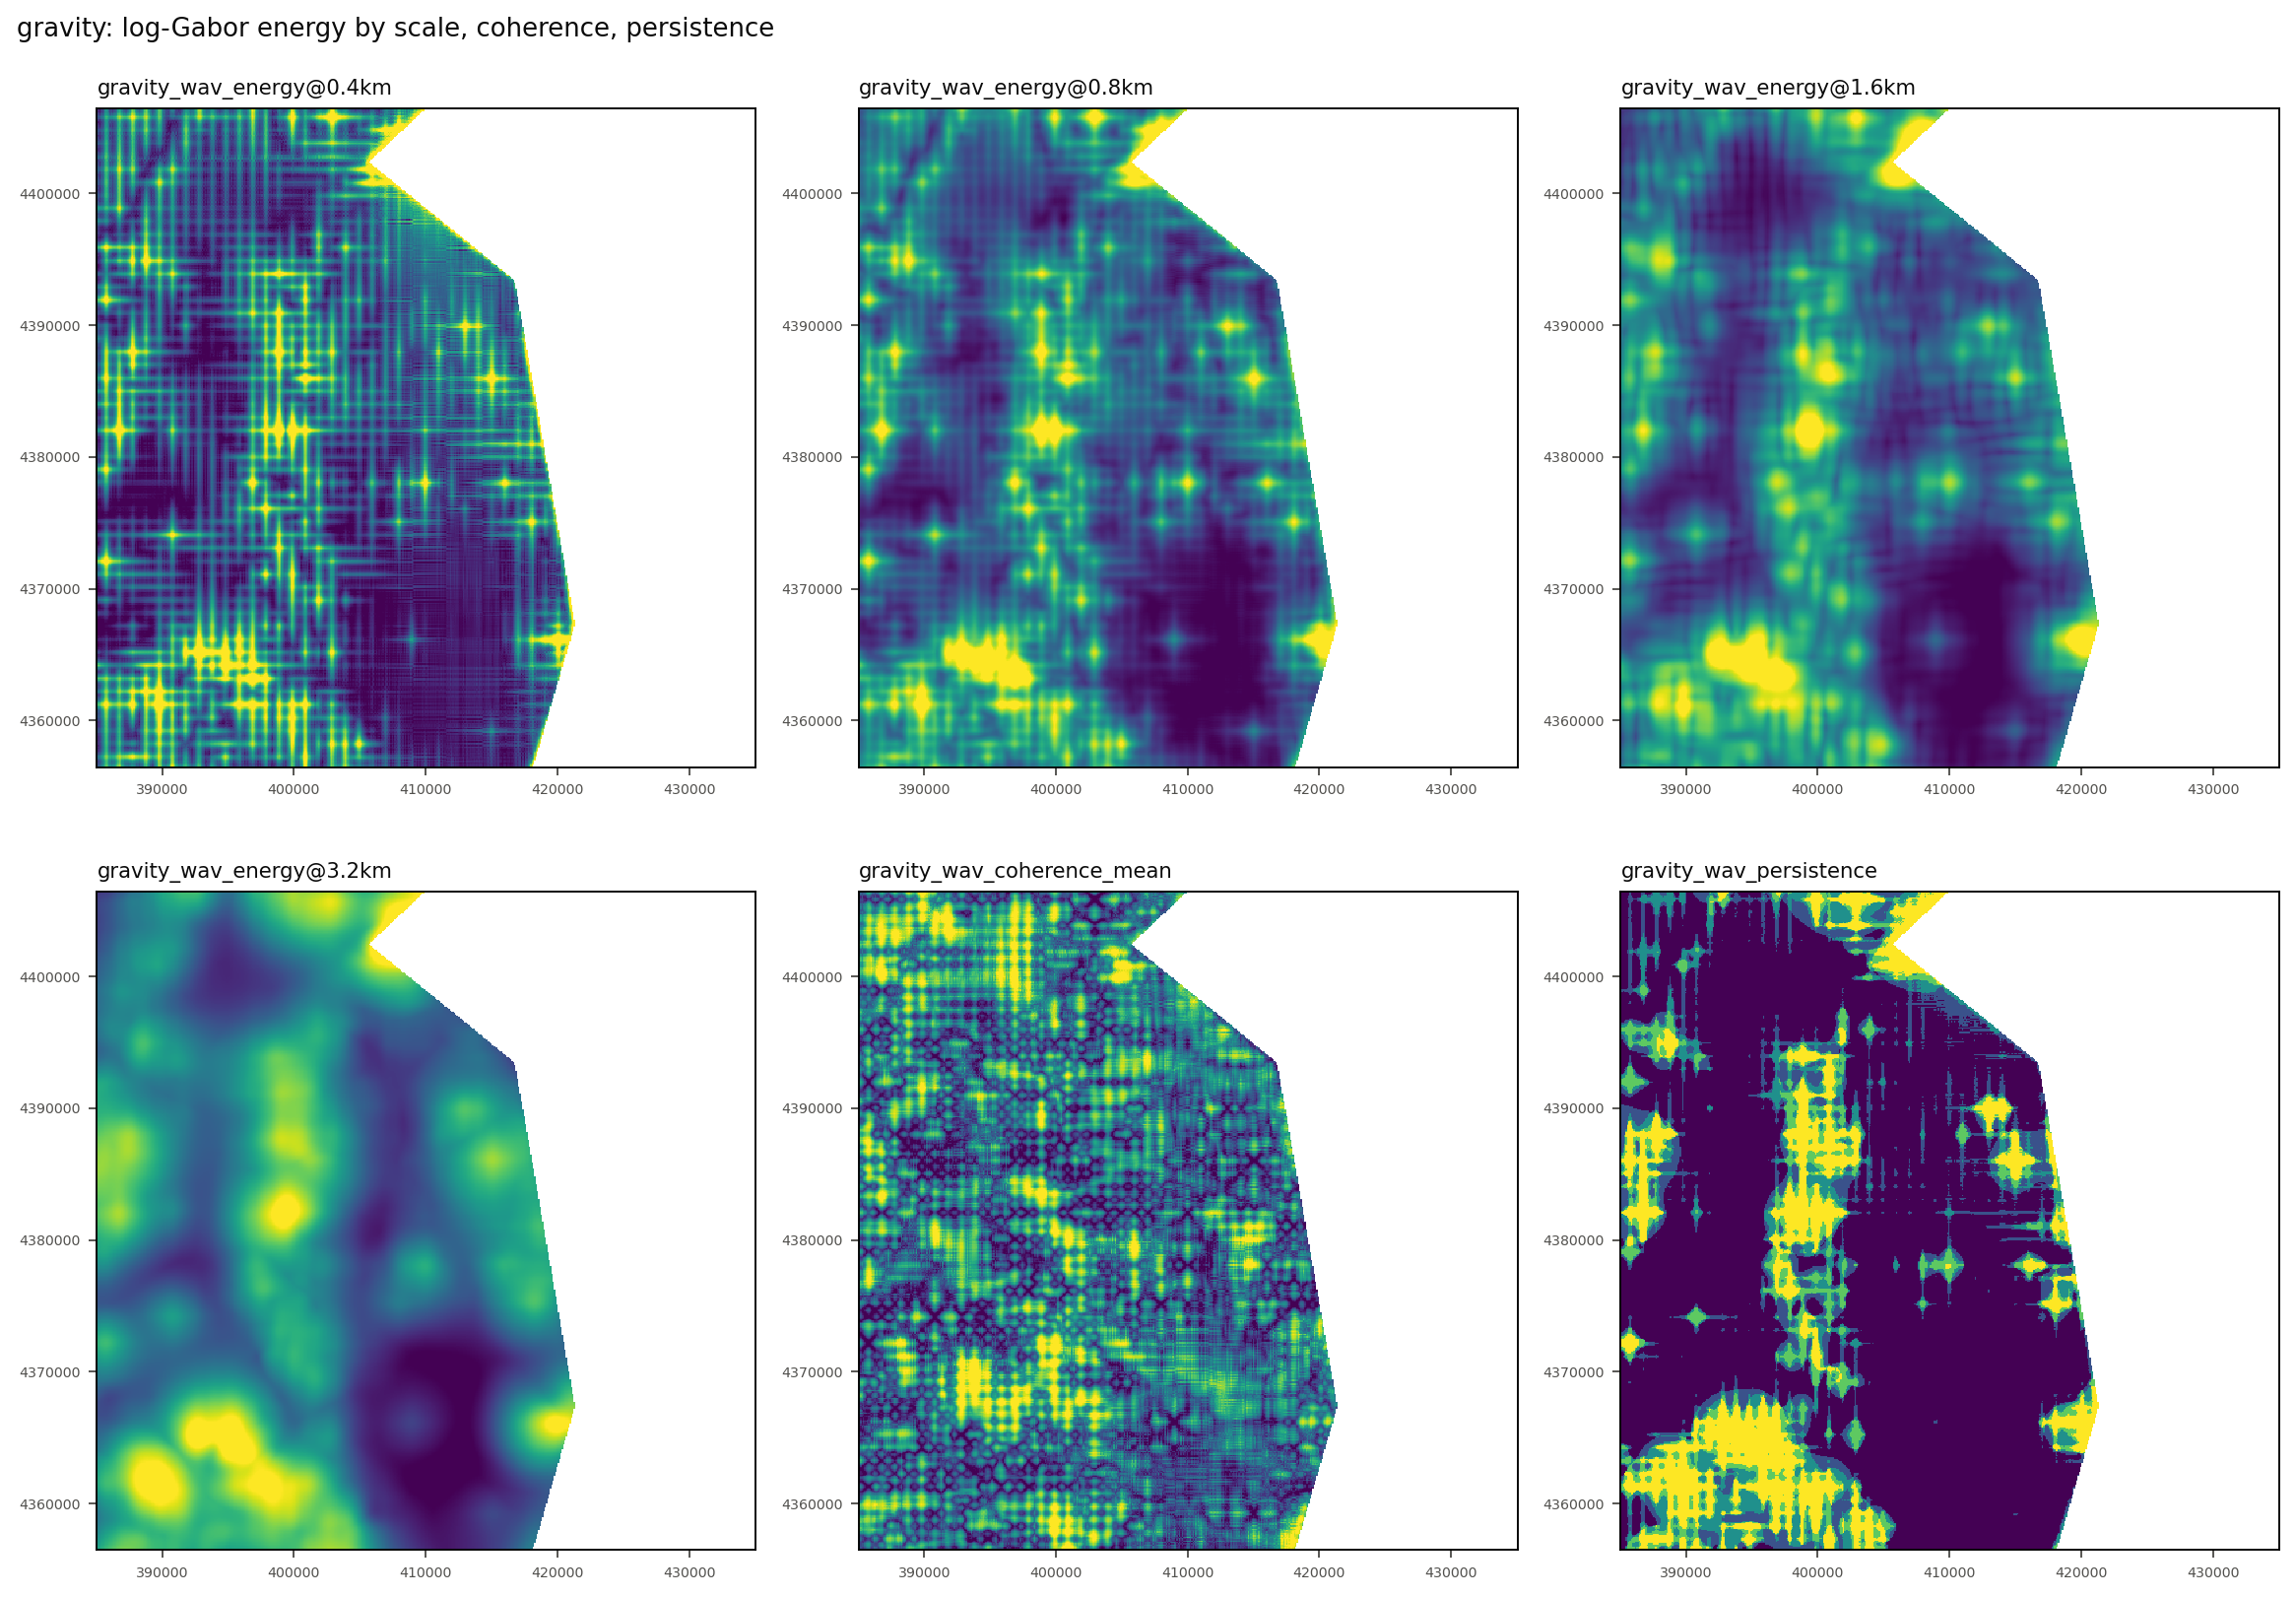

In [7]:
if m9.enabled('s03_spectral'):
    s03 = m9.s03_spectral()
    sub = 'spectral'
    tab('spectral_registry', sub, 40)
    sv = m9.ws.load_table('spectral_vs_existing', sub)
    if len(sv):
        display(sv.sort_values('abs_spearman', ascending=False).head(20))
    tab('screen_pooled', sub)
    tab('screen_unique_systems', sub)
    tab('gate1', sub)
    show(['feature_set_comparison', 'raw_vs_structural', 'mag_grav_agreement', 'fourier_magnetic', 'fourier_gravity',
          'wavelet_magnetic', 'wavelet_gravity'], f'{sub}/figures')

## 04. Training dataset and geographic CV

* **Research objective.** Build the input cube once, define training units, fit per-unit robust scaling on permitted geography only, and write the CV-A..F manifests.
* **Geological rationale.** Faults are spatially autocorrelated; geographic separation (buffered folds) and whole-system withholding are the only honest tests of generalisation and discovery.
* **Inputs.** Selected channels (02, 03), folds, discovery splits.
* **Method.** `geo_f<k>` (CV-A: inner-train patches, inner-val checkpointing, predict the validation zone), `disc_s<d>` (CV-B: withheld systems + ring weight 0, never negatives, never shown as context), optional `full`. Cube: float16 memory-mapped local channels + footprint, average-pooled cube for the low-resolution branch. Scaler: median / IQR on a random sample of the unit's permitted pixels. CV-D length strata, CV-E label-free geological domains (k-means of 20 km block descriptors), CV-F distance bands to known faults.
* **Expected artifacts.** `datasets/training_units.csv`, `normalization_manifest.json`, `channels_<variant>.json`, `datasets/cv/cv_a_geographic.csv`, `cv_b_discovery.csv`, `cv_d_length_strata.csv`, `cv_f_proximity.csv`, `domains.tif` / `.npz`, `cv_e_domain_blocks.csv`; cube in `cache/m9`.
* **Validation criteria.** Every scaler hash recorded; trained zones match the profile; domains are label-free.
* **Reload / resume.** The cube is rebuilt only when its channel list changes (key in the file name).

In [10]:
from pathlib import Path
import re
import inspect
import textwrap

run_file = Path("/content/GEMS/gems_bench/m9/run.py")
assert run_file.is_file(), f"Missing: {run_file}"

source = run_file.read_text()

# Restore original source if needed
backup = run_file.with_suffix(".py.bak")
if backup.exists():
    source = backup.read_text()

# Locate faulty expressions
old_local = 'len(meta["local"])'
old_pooled = 'len(meta["pooled"])'

assert old_local in source, "Cannot find n_local expression"
assert old_pooled in source, "Cannot find n_pooled expression"

# Count samples from saved artifacts, not PosixPath objects
helper = '''
def _m9_count_items(value):
    from pathlib import Path
    import numpy as np

    if value is None:
        return 0

    if isinstance(value, (list, tuple, dict, set)):
        return len(value)

    if isinstance(value, (str, Path)):
        path = Path(value)

        if not path.exists():
            raise FileNotFoundError(path)

        if path.suffix == ".npy":
            return int(np.load(path, mmap_mode="r").shape[0])

        if path.suffix == ".parquet":
            import pyarrow.parquet as pq
            return int(pq.ParquetFile(path).metadata.num_rows)

        if path.suffix == ".npz":
            with np.load(path) as data:
                lengths = [
                    data[k].shape[0]
                    for k in data.files
                    if data[k].ndim > 0
                ]
                if not lengths:
                    return 0
                if len(set(lengths)) != 1:
                    raise ValueError(f"Ambiguous NPZ lengths: {lengths}")
                return int(lengths[0])

        raise TypeError(f"Unsupported artifact: {path}")

    return len(value)
'''

# Insert helper just after imports, before first class/function
match = re.search(r"(?m)^(?:class|def)\s+\w+", source)
assert match, "Could not find a top-level class/function"

pos = match.start()
source = source[:pos] + helper + "\n\n" + source[pos:]

source = source.replace(
    old_local,
    '_m9_count_items(meta["local"])'
).replace(
    old_pooled,
    '_m9_count_items(meta["pooled"])'
)

# Validate before writing
compile(source, str(run_file), "exec")

run_file.write_text(source)

print("✅ Source patched successfully.")
print("✅ Original backup:", backup)
print("✅ Patched file:", run_file)

# Reload module in current Colab session
import sys
import importlib

for module_name in list(sys.modules):
    if module_name == "gems_bench.m9.run":
        importlib.reload(sys.modules[module_name])

print("✅ Module reloaded.")
print("⚠️ Recreate your m9 object using its original initialization cell.")

✅ Source patched successfully.
✅ Original backup: /content/GEMS/gems_bench/m9/run.py.bak
✅ Patched file: /content/GEMS/gems_bench/m9/run.py
✅ Module reloaded.
⚠️ Recreate your m9 object using its original initialization cell.


In [12]:
import sys
import inspect
import traceback
from pathlib import Path

run_file = Path("/content/GEMS/gems_bench/m9/run.py")
source = run_file.read_text()

print("=" * 65)
print("SOURCE PATCH STATUS")
print("=" * 65)

for expr in [
    'len(meta["local"])',
    'len(meta["pooled"])',
    '_m9_count_items(meta["local"])',
    '_m9_count_items(meta["pooled"])',
]:
    print(f"{expr}: {expr in source}")

print("\n" + "=" * 65)
print("ACTIVE M9 OBJECT")
print("=" * 65)

print("Class:", type(m9))
print("Module:", type(m9).__module__)
print("Source:", inspect.getfile(type(m9)))
print("S04 first line:", m9.s04_dataset.__code__.co_firstlineno)
print("S04 uses helper:",
      "_m9_count_items" in m9.s04_dataset.__code__.co_names)

print("\n" + "=" * 65)
print("REPRODUCING AND LOCATING ERROR")
print("=" * 65)

try:
    s04 = m9.s04_dataset()
    print("S04 SUCCESS")
except Exception as e:
    print("ERROR:", repr(e))

    tb = e.__traceback__
    while tb:
        frame = tb.tb_frame
        print(
            f"\n{frame.f_code.co_name}"
            f" | file={frame.f_code.co_filename}"
            f" | line={tb.tb_lineno}"
        )

        if frame.f_code.co_name == "fn":
            for key, value in frame.f_locals.items():
                if key == "meta" and isinstance(value, dict):
                    print("\nMETA:")
                    for k, v in value.items():
                        print(f"  {k}: {type(v).__name__} = {str(v)[:200]}")

        tb = tb.tb_next

    print("\nFULL TRACEBACK:")
    traceback.print_exc(limit=8)

SOURCE PATCH STATUS
len(meta["local"]): False
len(meta["pooled"]): False
_m9_count_items(meta["local"]): True
_m9_count_items(meta["pooled"]): True

ACTIVE M9 OBJECT
Class: <class 'gems_bench.m9.run.M9Research'>
Module: gems_bench.m9.run
Source: /content/GEMS/gems_bench/m9/run.py
S04 first line: 579
S04 uses helper: False

REPRODUCING AND LOCATING ERROR
ERROR: TypeError("object of type 'PosixPath' has no len()")

<cell line: 0> | file=/tmp/ipykernel_6090/2859649701.py | line=37

s04_dataset | file=/content/GEMS/gems_bench/m9/run.py | line=618

_stage | file=/content/GEMS/gems_bench/m9/run.py | line=324

fn | file=/content/GEMS/gems_bench/m9/run.py | line=608

META:
  key: str = 9ef4f2149217
  local: list = ['raw:mag_anom', 'raw:rtp', 'raw:tmi', 'raw:tmi_hg', 'raw:tmi_vg', 'raw:tc', 'raw:iso_grav_anom', 'raw:iso_grav_anom_hg', 'raw:iso_grav_anom_vg', 'raw:iso_grav_anom_slope', 'raw:det_elev', 'raw:det_el
  context_only: list = ['raw:geod_2ndinv', 'raw:geod_shearrate', 'raw:geod_dilatera

Traceback (most recent call last):
  File "/tmp/ipykernel_6090/2859649701.py", line 37, in <cell line: 0>
    s04 = m9.s04_dataset()
  File "/content/GEMS/gems_bench/m9/run.py", line 618, in s04_dataset
    return self._stage("s03_spectral", fp, fn, load)
           ~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/content/GEMS/gems_bench/m9/run.py", line 324, in _stage
    t = self.ws.load_table(kk, "tracing/units")
          ^^^^
  File "/content/GEMS/gems_bench/m9/run.py", line 608, in fn
    c), "mag_grav_agreement", f"{sub}/figures")
                                         ^^^^^^
TypeError: object of type 'PosixPath' has no len()


In [13]:
import importlib
import linecache
import sys

# Refresh displayed source lines
linecache.clearcache()

# Reload source module
mod = importlib.import_module("gems_bench.m9.run")
mod = importlib.reload(mod)

# Replace the old method on the currently instantiated class
new_cls = getattr(mod, type(m9).__name__)

type(m9).s04_dataset = new_cls.s04_dataset

print("S04 method refreshed.")
print(
    "Uses patched helper:",
    "_m9_count_items" in m9.s04_dataset.__code__.co_names
)

S04 method refreshed.
Uses patched helper: False


In [14]:
if m9.enabled('s04_dataset'):
    s04 = m9.s04_dataset()
    display(s04['units'])
    for n in ('cv_a_geographic', 'cv_b_discovery', 'cv_d_length_strata', 'cv_f_proximity'):
        tab(n, 'datasets/cv')

[m9] s04_dataset: computed in 93s -> /content/gems_work/outputs/m9_geofault_production
[sync out] 22 copied (0.6 MiB), 165 unchanged, 1s: ['outputs/m9_geofault_production']


,variant,unit,kind,zone,allowed_px,visible_fault_px,weighted_px,predict_px,n_local,n_pooled,cube_key,scaler_hash
0,core,geo_f0,cv,0,2321783,29980,2321783,1887813,92,113,9ef4f2149217,7566c8d22665
1,core,geo_f1,cv,1,2592917,29626,2592917,1548292,92,113,9ef4f2149217,3575aa88778c
2,core,geo_f2,cv,2,2235915,25611,2235915,1729747,92,113,9ef4f2149217,a620933008e2
3,core,disc_s0,disc,0,5165852,53407,5006964,1784107,92,113,9ef4f2149217,3b19202b5fab
4,core,disc_s1,disc,1,5165852,53516,5006983,1848909,92,113,9ef4f2149217,3b19202b5fab
5,core,disc_s2,disc,2,5165852,53704,5018257,1724912,92,113,9ef4f2149217,3b19202b5fab
6,recon_off,geo_f0,cv,0,2321783,29980,2321783,1887813,92,113,9ef4f2149217,7566c8d22665
7,recon_off,geo_f1,cv,1,2592917,29626,2592917,1548292,92,113,9ef4f2149217,3575aa88778c
8,recon_off,geo_f2,cv,2,2235915,25611,2235915,1729747,92,113,9ef4f2149217,a620933008e2
9,recon_off,disc_s0,disc,0,5165852,53407,5006964,1784107,92,113,9ef4f2149217,3b19202b5fab


,fold,trained_in_profile,train_px,inner_val_px,val_px,buffer_px,train_fault_px,val_fault_px
0,0,True,2321783,395014,1887813,490370,29980,18707
1,1,True,2592917,602174,1548292,351077,29626,22008
2,2,True,2235915,471946,1729747,630558,25611,20179


,split,trained_in_profile,withheld_systems,withheld_km,withheld_px,ignore_px,eval_zone_px
0,0,True,38,812.24,7581,159708,1784107
1,1,True,38,807.84,7472,159348,1848909
2,2,True,44,783.53,7284,148168,1724912


,task,zone,length_bin_km,n_systems
0,disc_official,0,"[0.0, 1.0)",0
1,disc_official,0,"[1.0, 2.0)",0
2,disc_official,0,"[2.0, 5.0)",0
3,disc_official,0,"[5.0, inf)",38
4,disc_official,1,"[0.0, 1.0)",0
5,disc_official,1,"[1.0, 2.0)",0
6,disc_official,1,"[2.0, 5.0)",0
7,disc_official,1,"[5.0, inf)",38
8,disc_official,2,"[0.0, 1.0)",0
9,disc_official,2,"[1.0, 2.0)",0


,zone,band,truth_px,share
0,0,<1 km,0,0.000000
1,0,1-3 km,2383,0.314421
2,0,>3 km,5196,0.685579
3,1,<1 km,0,0.000000
4,1,1-3 km,2119,0.283706
5,1,>3 km,5350,0.716294
6,2,<1 km,0,0.000000
7,2,1-3 km,2282,0.313375
8,2,>3 km,5000,0.686625


## 05. Synthetic fault-map corruption

* **Research objective.** Teach the network to reconstruct incomplete maps (truncated endpoints, interior gaps, omitted segments / branches, displaced traces, removed systems) while still discovering faults with no map at all.
* **Geological rationale.** Mapping stops where access or exposure stops, not where faults stop. The test-time known map is incomplete in exactly these ways, and new faults may be continuations or corrections next to it.
* **Inputs.** Visible labels of each training unit, the discovery system map.
* **Method.** Mixture none / partial / heavy (35 / 40 / 25 %); operators applied per patch to visible labels only; the context channel shows the damaged map plus a flag (1 = a map is given); seg targets stay the full visible map, but pixels shown as context get weight 0.1 (copying earns little); removed geometry drives L6. CV-C benchmark sets: M7 corruption classes on each trained fold, systems assigned to folds before damage.
* **Expected artifacts.** `corruption/samples/<unit>.npz`, `samples_<unit>.csv`, `corruption_samples.png`, `operation_counts.csv`, `corruption_manifest.json`, `corruption/benchmark/fold<k>.npz`, `benchmark_protocol.csv`.
* **Validation criteria.** Leakage audit: without displacement, the context never shows a pixel that is not a visible label (raises otherwise).
* **Reload / resume.** Fingerprinted; benchmark sets are seeded.

In [17]:
# ================================================================
# GEMS M9 — HOTFIX: pooled metadata path/name collision
# No restart, no reload, no previous stage reruns
# ================================================================

import types
import numpy as np
from pathlib import Path

# Preserve original implementation, including across repeated patches
if not hasattr(m9, "_gems_original_cube_for"):
    m9._gems_original_cube_for = getattr(
        m9, "_original_cube_for", m9.cube_for
    )

def _gems_fixed_cube_for(self, vcfg):
    meta, cube, pooled_cube = self._gems_original_cube_for(vcfg)
    meta = dict(meta)

    # Preserve physical artifact locations
    if isinstance(meta.get("pooled"), (str, Path)):
        meta["pooled_path"] = str(meta["pooled"])

    # Recover original channel definitions from cube metadata
    local_names = list(meta["local"])
    context_names = list(meta.get("context_only", []))
    pooled_names = local_names + context_names

    # Strict checks: never silently use incorrect dimensions
    assert len(local_names) == cube.shape[0], (
        f"Local channels: {len(local_names)} != {cube.shape[0]}"
    )
    assert len(pooled_names) == pooled_cube.shape[0], (
        f"Pooled channels: {len(pooled_names)} != {pooled_cube.shape[0]}"
    )
    assert len(set(pooled_names)) == len(pooled_names), (
        "Duplicate pooled channel names detected"
    )

    meta["local"] = local_names
    meta["pooled"] = pooled_names

    return meta, cube, pooled_cube

# Patch this instance only
m9.cube_for = types.MethodType(_gems_fixed_cube_for, m9)

# Validate actual S05 and S06 requirements before proceeding
from gems_bench.m9 import dataset as DS
from gems_bench.m9 import model as MD
from gems_bench.m9.features import channel_groups

print("VALIDATING ALL M9 VARIANTS")
print("=" * 65)

for variant in m9.variants():
    vc = m9.variant_cfg(variant)
    meta, cube, pooled_cube = m9.cube_for(vc)

    groups = channel_groups(m9, vc)
    spec = MD.net_spec(meta, groups, vc)

    assert spec["n_pool"] == pooled_cube.shape[0]
    assert len(meta["local"]) == cube.shape[0]

    print(
        f"✅ {variant}: "
        f"local={len(meta['local'])}, "
        f"pooled={spec['n_pool']}, "
        f"cube={tuple(cube.shape)}"
    )

print("\n✅ HOTFIX ACTIVE — S05 and S06 metadata validated")
print("✅ Existing m9 instance preserved")
print("✅ No runtime restart required")

VALIDATING ALL M9 VARIANTS
✅ core: local=92, pooled=113, cube=(92, 3730, 3292)
✅ recon_off: local=92, pooled=113, cube=(92, 3730, 3292)
✅ stage_c: local=92, pooled=113, cube=(92, 3730, 3292)
✅ no_spectral: local=80, pooled=101, cube=(80, 3730, 3292)

✅ HOTFIX ACTIVE — S05 and S06 metadata validated
✅ Existing m9 instance preserved
✅ No runtime restart required


[m9] s05_corruption: computed in 256s -> /content/gems_work/outputs/m9_geofault_production
[sync out] 17 copied (0.5 MiB), 186 unchanged, 0s: ['outputs/m9_geofault_production']


,operation,count,unit
0,whole_system_removal,26,geo_f0
1,segment_omission,29,geo_f0
2,branch_omission,17,geo_f0
3,endpoint_truncation,29,geo_f0
4,interior_removal,22,geo_f0
5,local_displacement,26,geo_f0
6,mode_partial,15,geo_f0
7,mode_none,19,geo_f0
8,mode_heavy,14,geo_f0


,class,fold,n_events,removed_px
0,short_fault,0,80,633
1,incomplete_network,0,17,256
2,missing_branch,0,72,442
3,endpoint_truncation,0,235,4633
4,interior_gap,0,19,585
5,lateral_shift,0,31,503
6,short_fault,1,135,1263
7,incomplete_network,1,25,374
8,missing_branch,1,71,494
9,endpoint_truncation,1,362,6131


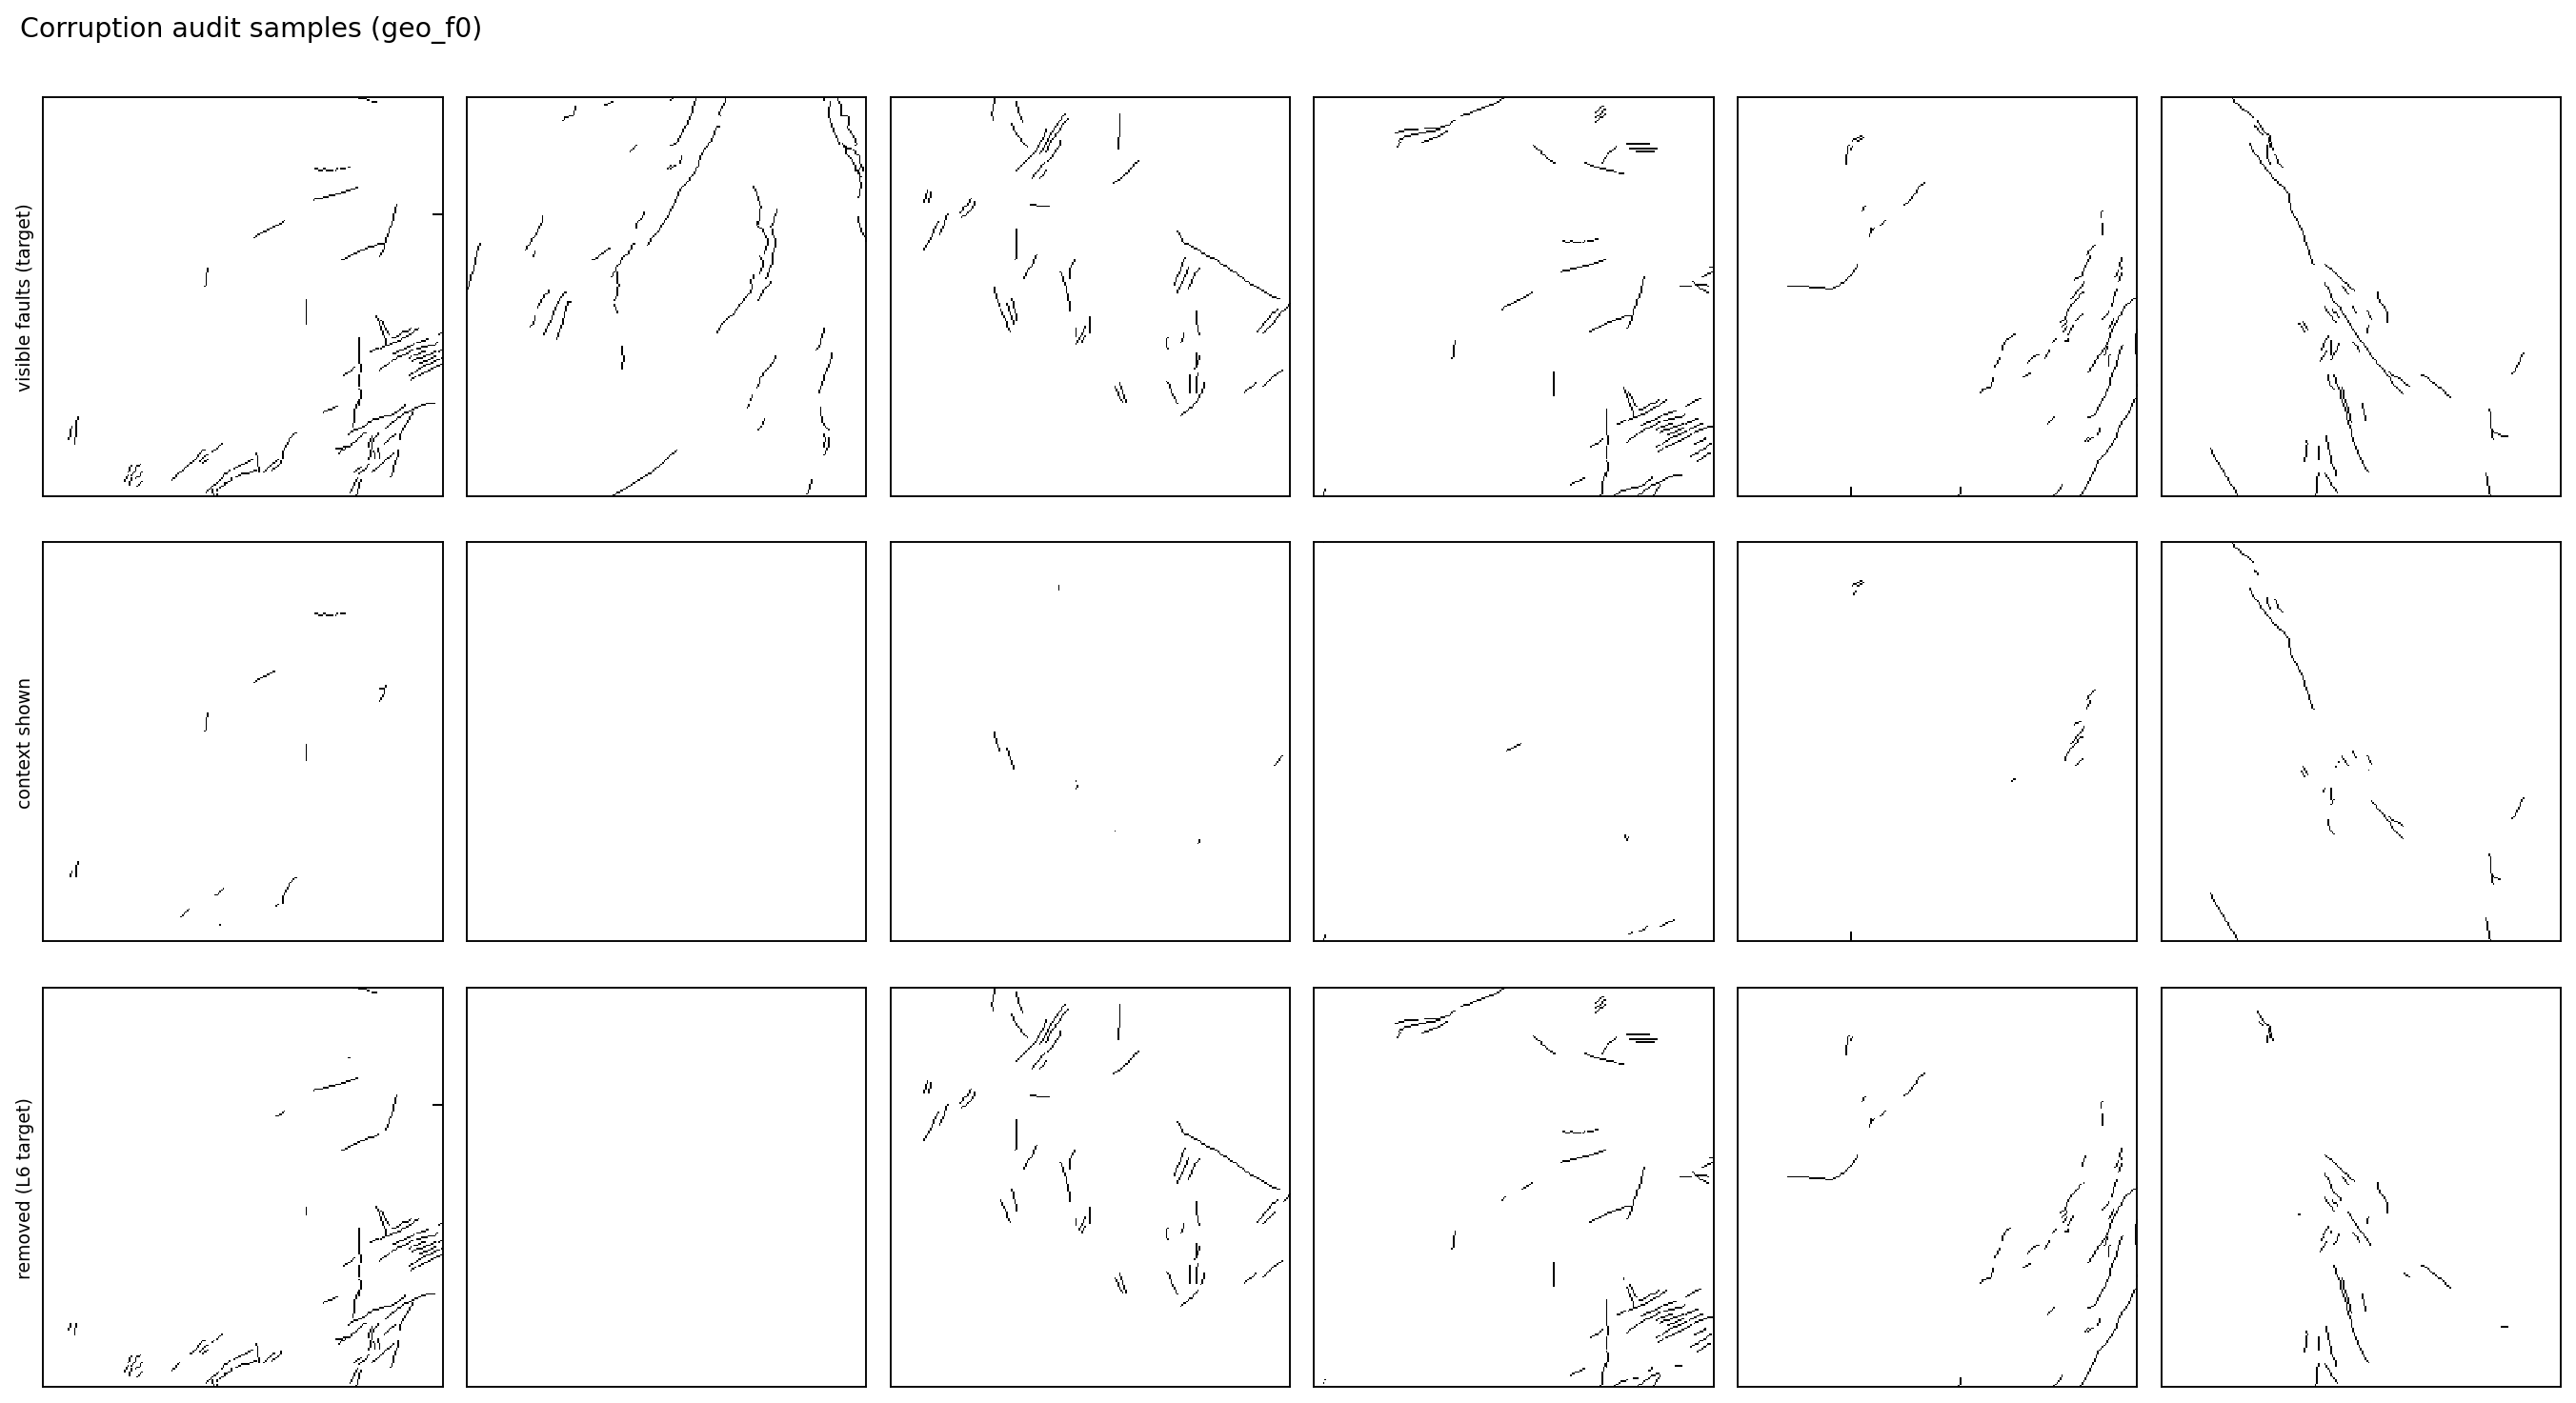

In [18]:
if m9.enabled('s05_corruption'):
    s05 = m9.s05_corruption()
    tab('operation_counts', 'corruption')
    tab('benchmark_protocol', 'corruption')
    for p in sorted((OUT / 'corruption' / 'samples').glob('*.png')):
        display(Image(filename=str(p)))

## 06. Multiscale model architecture

* **Research objective.** One practical multi-resolution, multi-task network family (GeoFaultNet); no architecture zoo.
* **Geological rationale.** Fault localisation is local (100 m), its plausibility regional (km). Modalities must keep separate evidence (no forced agreement); orientation is axial (θ ≡ θ + 180°).
* **Inputs.** `channels_<variant>.json`, model block of the configuration.
* **Method.** Modality stems (raw, structural, spectral, optional DEM, map context) → per-pixel gated fusion → residual U-Net (P … P/16) with a 4× wider low-resolution context branch aligned at the bottleneck + FiLM → heads: dense evidence, (cos 2θ, sin 2θ), endpoint, junction.
* **Expected artifacts.** `models/architecture.csv` (parameters, channels per stem), `models/net_spec_<variant>.json`.
* **Validation criteria.** Builds on CPU; parameter count stays in the few-million range (T4-friendly).
* **Reload / resume.** Cheap; fingerprinted.

In [19]:
if m9.enabled('s06_architecture'):
    s06 = m9.s06_architecture()
    display(s06['architecture'])

[m9] s06_architecture: computed in 0s -> /content/gems_work/outputs/m9_geofault_production
[sync out] 9 copied (0.1 MiB), 202 unchanged, 0s: ['outputs/m9_geofault_production']


,variant,n_params,n_raw,n_struct,n_spectral,n_dem,n_pooled,patch_px,context_factor,widths,fusion
0,core,3637657,15,65,12,0,113,256,4,"[32, 64, 128, 192]",gated
1,recon_off,3637657,15,65,12,0,113,256,4,"[32, 64, 128, 192]",gated
2,stage_c,3637657,15,65,12,0,113,256,4,"[32, 64, 128, 192]",gated
3,no_spectral,3627752,15,65,0,0,101,256,4,"[32, 64, 128, 192]",gated


## 07. Multi-task losses

* **Research objective.** A staged, incomplete-label-aware objective whose terms are switched on in a fixed curriculum, never tuned jointly.
* **Geological rationale.** Unmapped faults exist: unlabeled background is a weak negative. Thin, continuous, oriented traces need connectivity and orientation supervision; endpoints / junctions carry network topology.
* **Inputs.** Loss block, variants.
* **Method.** L1 focal PU-weighted BCE; L2 kernel Tversky surrogate (α 0.2, β 0.8, 300 m) — a surrogate, the exact scorer evaluates; L3 skeleton recall / clDice; L4 doubled-angle cosine; L5 sparse topology heatmaps; L6 reconstruction; L7 optional EMA consistency. Curriculum: A (L1 + L6), B (+ L4 + L5), C (+ enabled Stage-C terms).
* **Expected artifacts.** `training/loss_schedule.csv`.
* **Validation criteria.** Stage-C terms enter production only through the `stage_c` variant after it beats `core` (section 09 `variant_deltas`).
* **Reload / resume.** Cheap; fingerprinted.

In [20]:
if m9.enabled('s07_losses'):
    display(m9.s07_losses()['schedule'])

[m9] s07_losses: computed in 0s -> /content/gems_work/outputs/m9_geofault_production
[sync out] 5 copied (0.0 MiB), 210 unchanged, 0s: ['outputs/m9_geofault_production']


,variant,stage,l1,l2,l3,l4,l5,l6
0,core,A,1.0,0.0,0.0,0.0,0.0,1.0
1,core,B,1.0,0.0,0.0,0.2,0.2,1.0
2,core,C,1.0,0.5,0.0,0.2,0.2,1.0
3,recon_off,A,1.0,0.0,0.0,0.0,0.0,1.0
4,recon_off,B,1.0,0.0,0.0,0.2,0.2,1.0
5,recon_off,C,1.0,0.5,0.0,0.2,0.2,1.0
6,stage_c,A,1.0,0.0,0.0,0.0,0.0,1.0
7,stage_c,B,1.0,0.0,0.0,0.2,0.2,1.0
8,stage_c,C,1.0,0.5,0.2,0.2,0.2,1.0
9,no_spectral,A,1.0,0.0,0.0,0.0,0.0,1.0


## 08. Training and checkpoints (GPU)

* **Research objective.** Train every (variant, unit) of the profile reproducibly and resumably.
* **Geological rationale.** Discovery units withhold whole systems; their epochs follow the geo units' median best epoch (no peeking at the withheld truth).
* **Inputs.** Cube, targets, corruption, losses.
* **Method.** AMP (bf16 on Ampere+, fp16 + scaler on T4), gradient accumulation, clipping, OneCycle, CPU patch prefetch (the full cube never goes to VRAM), inner-validation checkpoint score = official-style DTI with no map context, patience, collapse guard, OOM back-off, `best_and_latest` atomic checkpoints synced to Drive, `max_runtime_min` clean stop.
* **Expected artifacts.** `models/checkpoints/<variant>/<unit>_model.pt` (+ resume files while running), `models/<variant>__<unit>_scaler.json`, `training/logs/<variant>__<unit>.csv` (loss decomposition per epoch), `training/training_units.csv`, `reports/model_registry/model_registry.csv` (sha256), `training/loss_components.png`.
* **Validation criteria.** Status `complete` / `early_stopped`; `stopped_collapse` means the PU weighting is too lax for that unit (inspect `loss_unlabeled_mean_p`).
* **Reload / resume.** Re-run the cell: finished units are reused by spec hash, interrupted ones resume from the last epoch.

In [ ]:
if m9.enabled('s08_training'):
    s08 = m9.s08_training()               # None when interrupted by the runtime budget: re-run to resume
    tab('training_units', 'training')
    show(['loss_components'], 'training')

[m9] s08 core/geo_f0 ep 1/40 [A] loss_l1 0.1966 inner 0.1075 (478s)
[sync out] 3 copied (69.6 MiB), 0 unchanged, 1s: ['outputs/m9_geofault_production/models/checkpoints/core/geo_f0_latest.pt', 'outputs/m9_geofault_production/models/checkpoints/core/geo_f0_latest.json', 'outputs/m9_geofault_production/models/checkpoints/core/geo_f0_best.pt']
[m9] s08 core/geo_f0 ep 2/40 [A] loss_l1 0.0901 inner 0.1364 (448s)
[m9] s08 core/geo_f0 ep 3/40 [A] loss_l1 0.0798 inner 0.1358 (454s)
[sync out] 2 copied (55.6 MiB), 0 unchanged, 1s: ['outputs/m9_geofault_production/models/checkpoints/core/geo_f0_latest.pt', 'outputs/m9_geofault_production/models/checkpoints/core/geo_f0_latest.json']
[m9] s08 core/geo_f0 ep 4/40 [A] loss_l1 0.0697 inner 0.1515 (454s)
[m9] s08 core/geo_f0 ep 5/40 [A] loss_l1 0.0552 inner 0.1483 (451s)
[sync out] 2 copied (55.6 MiB), 0 unchanged, 1s: ['outputs/m9_geofault_production/models/checkpoints/core/geo_f0_latest.pt', 'outputs/m9_geofault_production/models/checkpoints/core/ge

## 09. Geographic and discovery validation — Gates 2 and 3

* **Research objective.** Measure the dense channel under CV-A..F against the champion on identical units, and decide whether the redesign (Gate 2) and the reconstruction task (Gate 3) earn their place.
* **Geological rationale.** Geographic transfer, whole-system discovery, short faults, domain transfer and proximity to known faults fail for different reasons; one aggregate hides them.
* **Inputs.** Checkpoints, CV-C sets, champion maps.
* **Method.** Each unit predicts only its own held-out mask (geo: no context; disc: no context AND known retained map). Nested (rep, frac) per zone; PILOT borrows the champion's choice (labelled). M7's comparison re-scores every map: pooled + worst-zone DTI, system / length / short-fault recall, density, regions, known-fault proximity, paired zone deltas, spatial block bootstrap. CV-C reconstruction recall with damaged-map vs no context; CV-D length strata; CV-E domain DTI; variant deltas.
* **Expected artifacts.** `predictions/<variant>/*.npz`, `predictions/oof/<variant>_seg.tif`, `predictions/discovery/<variant>_seg.tif`, `validation/maps/m9_dense_*`, `validation/metrics/{method_pooled, method_per_zone, paired_zone_deltas, bootstrap, system_hits, known_proximity, regional_dti, reconstruction(_pooled), length_strata, domain_dti, variant_deltas}`, `reports/decision_verdicts.csv`, `validation/gate2.csv`, `gate3.csv`, figures in `validation/figures/`.
* **Validation criteria.** Gate 2 PROMOTE (all promotion rules) or COMPLEMENT (≥ 3 unique systems, or a fusion gain ≥ 0.005 in section 16); Gate 3 RETAIN_RECONSTRUCTION when reconstruction recall rises ≥ 0.02 without losing ≥ 0.005 discovery / geographic DTI (needs `recon_off`, FULL).
* **Reload / resume.** Predictions are reused file by file; the stage is fingerprinted.

In [ ]:
if m9.enabled('s09_validation'):
    s09 = m9.s09_validation()
    sub = 'validation/metrics'
    tab('method_pooled', sub, 40)
    pz = m9.ws.load_table('paired_zone_deltas', sub)
    if len(pz):
        display(pz.pivot_table(index=['task', 'method'], columns='zone', values='delta_vs_ref'))
    tab('bootstrap', sub)
    tab('reconstruction_pooled', sub, 40)
    tab('variant_deltas', sub)
    tab('gate2', 'validation')
    tab('gate3', 'validation')
    show(['geographic_fold_performance', 'whole_system_recall', 'short_fault_behaviour', 'known_fault_distance',
          'geographic_failure_modes'], 'validation/figures')

## 10. Dense structural prediction analysis

* **Research objective.** Check the auxiliary heads: is the predicted orientation right where it is confident; are endpoints and junctions found; how does the score relate to proximity of truth?
* **Geological rationale.** Tracing (11) relies on the orientation field; topology heads justify branch / stop decisions.
* **Inputs.** Held-out `core` predictions.
* **Method.** Axial error vs label strike by confidence bin; endpoint / junction peak recall and precision within 2 px; reliability (share within 300 m of truth by score bin — not calibration: unlabelled faults count as misses).
* **Expected artifacts.** `dense_analysis/orientation_error.csv`, `endpoint_junction.csv`, `reliability.csv`, `reliability.png`.
* **Validation criteria.** Orientation error should fall with confidence; if not, tracing must lean on evidence, not orientation (`w_orient`).
* **Reload / resume.** Fingerprinted.

In [ ]:
if m9.enabled('s10_dense_analysis'):
    s10 = m9.s10_dense_analysis()
    for n in ('orientation_error', 'endpoint_junction', 'reliability'):
        tab(n, 'dense_analysis')
    show(['reliability'], 'dense_analysis')

## 11. Graph and beam-search fault tracing — Gate 4

* **Research objective.** Turn dense evidence + orientation into explicit fault hypotheses (with branches and alternatives) and measure, before any ranker, whether they cover systems the dense map misses.
* **Geological rationale.** Faults are continuous, gently curving, may be locally invisible (gaps) and branch; a path search with orientation-aware costs can bridge weak evidence that pixel thresholds drop.
* **Inputs.** Held-out dense predictions of each trained unit.
* **Method.** Baseline: crest skeleton + minimum-cost bridges. Beam search (vectorised over seeds, both directions, controlled turning, gap tolerance, branch re-tracing), optional stochastic beams; dedup by overlap; nothing is permanently thresholded away (statistics kept for ranking). Oracle: system recall vs density, additional systems over the dense map at the same pixel count.
* **Expected artifacts.** `tracing/units/<unit>.{npz,csv}`, `tracing/candidates.gpkg`, `tracer_log.csv`, `tracing/oracle/{oracle_curve, pooled_oracle, systems_at_max_density, gate4}.csv`, `oracle_curve.png`, `tracing_failures_*.png`.
* **Validation criteria.** Gate 4 CONTINUE when system recall at 40 km / 100 km² ≥ 0.30 and ≥ 3 additional systems; STOP → sections 14–15 refuse (`tracing.force_rank` overrides) and the dense channel remains the production route.
* **Reload / resume.** Trace sets are saved per unit; fingerprinted.

In [ ]:
if m9.enabled('s11_tracing'):
    s11 = m9.s11_tracing()
    tab('tracer_log', 'tracing')
    tab('pooled_oracle', 'tracing/oracle')
    tab('gate4', 'tracing/oracle')
    show(['oracle_curve'], 'tracing/oracle')
    for p in sorted((OUT / 'tracing').glob('tracing_failures_*.png'))[:3]:
        display(Image(filename=str(p)))

## 12. Monte Carlo uncertainty *(P2, off by default)*

* **Research objective.** Quantify which traced structures are stable under plausible evidence / processing perturbations (MC-A) and which alternatives a stochastic tracer proposes (MC-B); MC-C = seeded ensembles (`n_seeds`).
* **Geological rationale.** Edge positions depend on noise, registration, smoothing and thresholds; real structures should survive moderate perturbation.
* **Inputs.** Held-out dense predictions, section-11 traces.
* **Method.** 16 realisations (PILOT): correlated noise, one registration shift per realisation (shared source perturbed once), smoothing / orientation / seed jitter → re-trace; stochastic beams → occupancy, branch frequency; convergence check (raise realisations only if not converged AND Gate 5 shows value).
* **Expected artifacts.** `monte_carlo/stability.csv`, `convergence.csv`, `realization_params.csv`, `occupancy_<unit>.{npz,tif}`, `mc_only_coverage.csv`, `assumptions.json`, `mc_<unit>.png`, `reports/gate5.csv` (monte_carlo row).
* **Validation criteria.** Gate 5 INCLUDE only with ≥ 2 MC-only systems or a ranking gain ≥ 0.003 (`all_mc` vs `all`, section 16). Occupancy is never called a probability.
* **Reload / resume.** Fingerprinted.

In [ ]:
if m9.enabled('s12_monte_carlo'):
    s12 = m9.s12_monte_carlo()
    st = m9.ws.load_table('stability', 'monte_carlo')
    if len(st):
        display(st.describe().T)
    tab('convergence', 'monte_carlo')
    tab('mc_only_coverage', 'monte_carlo')
    tab('gate5', 'reports')
    for p in sorted((OUT / 'monte_carlo').glob('mc_*.png'))[:2]:
        display(Image(filename=str(p)))

## 13. Optional RL tracing *(P2, challenger only)*

* **Research objective.** Test whether a learned tracer beats beam search on held-out systems.
* **Geological rationale.** Experts trace faults by local decisions (continue, turn, jump a gap, branch, stop); a policy might learn those decisions from mapped traces.
* **Inputs.** Held-out dense predictions; truth of OTHER zones only (2 km buffer around the evaluated unit).
* **Method.** Gymnasium-compatible environment (advance / turn / connect / branch / stop); behavioural cloning on greedy expert moves; PPO / DQN via stable-baselines3 when installed (`rl.algorithm`); learned edge cost (logistic regression) used inside beam search; all scored with the same seeds and oracle as beam search.
* **Expected artifacts.** `rl/tracer_comparison.csv`, `reports/gate5.csv` (rl row).
* **Validation criteria.** Promote a challenger only if it recovers ≥ 2 more held-out systems than beam search at the gate density; otherwise beam search stays.
* **Reload / resume.** Fingerprinted; never required by the production path.

In [ ]:
if m9.enabled('s13_rl'):
    s13 = m9.s13_rl()
    tab('tracer_comparison', 'rl', 40)
    tab('gate5', 'reports')

## 14. Candidate-level geological features *(needs Gate 4 CONTINUE)*

* **Research objective.** Describe each traced hypothesis with interpretable, provenance-tracked evidence.
* **Geological rationale.** A fault juxtaposing contrasting units shows a localised fault-normal step; lithological contacts and basin edges also produce edges, so cross-modal consistency, spectral fabric and network context help separate them.
* **Inputs.** Trace sets, dense / legacy predictions, physics and spectral layers, optional Monte Carlo stability.
* **Method.** M7 descriptors + tracing statistics, fault-normal contrasts at 200 / 400 / 800 m (magnetic, gravity, conductivity, basement), spectral / cross-modal means, M9 and B0 / B1 support and disagreement, context percentiles, Monte Carlo stability (`has_mc` explicit). Labels: 1 near scored truth, 0 far, −1 unlabelled (dropped, never negative). IDs / zones / seed positions excluded from features.
* **Expected artifacts.** `candidates/candidate_table.parquet`, `candidates/units/*`, `feature_groups.csv`, `feature_provenance.csv`, `label_balance.csv`, `candidates.gpkg`, `candidate_fault_normal_profiles.png`.
* **Validation criteria.** Every feature belongs to a group; label balance is reported per task.
* **Reload / resume.** Fingerprinted.

In [ ]:
if m9.enabled('s14_candidate_features'):
    s14 = m9.s14_candidate_features()     # None (logged) when Gate 4 is STOP
    tab('label_balance', 'candidates')
    fg = m9.ws.load_table('feature_groups', 'candidates')
    if len(fg):
        display(fg.groupby('group').size())
    show(['candidate_fault_normal_profiles'], 'candidates')

## 15. XGBoost / LightGBM / CatBoost

* **Research objective.** A fair three-library comparison; choose the model with the best deployable geometry, preferring steadiness over a marginal aggregate gain.
* **Geological rationale.** The structured channel only matters if verified candidates add systems the dense map misses at a controlled density.
* **Inputs.** Candidate table, trace sets.
* **Method.** Identical tables, folds (leave-one-zone-out, 2 km buffer, linked-network exclusion), supervision, weights, seeds and budgets; candidate AUC-PR / ROC-AUC (reported, not optimised), top-10 % recall, system recall at the gate density, false-candidate share, rasterised official-style DTI with nested frac, seed stability; optional LambdaMART.
* **Expected artifacts.** `gbm/{summary, per_zone, candidate_metrics, system_recall, audit, availability, stability, choice, feature_importance}.csv`, `gbm/models/<library>_all.joblib`, `validation/maps/m9_struct_*`, `validation/maps/m9_structured`, `library_comparison.png`.
* **Validation criteria.** Choice = best pooled DTI; libraries within 0.003 compete on their worst zone.
* **Reload / resume.** Fingerprinted.

In [ ]:
if m9.enabled('s15_gbm_benchmark'):
    s15 = m9.s15_gbm_benchmark()
    tab('availability', 'gbm')
    tab('summary', 'gbm', 40)
    tab('choice', 'gbm')
    tab('stability', 'gbm')
    show(['library_comparison'], 'gbm')

## 16. Dense + structured fusion — Gate 6

* **Research objective.** Decide, leakage-safely, whether any M9 system replaces the B0 / B1 champion.
* **Geological rationale.** Dense evidence keeps faint, unlinked signal; structured traces keep continuity; legacy maps carry what B0 / B1 already learned. Ranking must not erase faint dense evidence.
* **Inputs.** Held-out dense maps, structured scores, champion maps.
* **Method.** Per-zone percentile channels D / S / L; fusions D+S, D+L, D+S+L on a weight simplex; weights, representation and budget nested on the other zones; the 300 m ring evaluated separately (never in the champion by default); M7 comparison + verdicts; Gate 6 promotes only a reproducible method that passes every rule. Gate 2 is updated with the fusion gain, Gate 5 with the Monte Carlo ranking gain.
* **Expected artifacts.** `fusion/{grid, summary, per_zone, ring, gate6}.csv`, `fusion/method_parameters.json`, `validation/metrics/*` (final), `reports/decision_verdicts.csv`, `dense_vs_structured.png`.
* **Validation criteria.** PROMOTE only with pooled gain ≥ 0.01, ≥ 2/3 zone wins, worst zone ≥ −0.01, geographic drop ≤ 0.01, bootstrap P(Δ > 0) ≥ 0.8, short-fault recall drop ≤ 0.02 — and ≥ 3 zones (PILOT can never promote).
* **Reload / resume.** Fingerprinted.

In [ ]:
if m9.enabled('s16_fusion'):
    s16 = m9.s16_fusion()
    tab('summary', 'fusion', 40)
    tab('ring', 'fusion')
    tab('method_pooled', 'validation/metrics', 60)
    tab('decision_verdicts', 'reports', 40)
    tab('gate6', 'fusion')
    show(['dense_vs_structured'], 'fusion')

## 17. Full-area inference *(GPU recommended)*

* **Research objective.** Produce the full-grid dense heads (and optional full-region traces) for submission.
* **Geological rationale.** At test time the whole known map is given: the production context is the known map (configurable).
* **Inputs.** `core` checkpoints (fold average or `full`), cube, chosen ranker.
* **Method.** 1024 px tiles with a 64 px halo, Hann-blended patches, linear seam ramps, resumable per tile, CPU / GPU fallback; full-region traces scored by the chosen library refitted on every labelled primary-task row.
* **Expected artifacts.** `predictions/full/core_heads.tif` (seg, cos 2θ, sin 2θ, endpoint, junction), `inference/tiles/*`, `tracing/full_region.gpkg`, `inference/inference_manifest.json`.
* **Validation criteria.** No NaN inside the footprint; tiles complete.
* **Reload / resume.** Re-run: finished tiles are skipped.

In [ ]:
if m9.enabled('s17_inference'):
    s17 = m9.s17_inference()
    print(json.dumps(m9.read_json('inference/inference_manifest.json'), indent=1, default=str))

## 18. Submission validation *(never uploads)*

* **Research objective.** Champion and fallback GeoTIFFs that pass every check.
* **Geological rationale.** —
* **Inputs.** Gate 6, method parameters, full-area products, champion member maps.
* **Method.** Fallback = B0 / B1 champion (ring 0). M9 champion only on Gate 6 PROMOTE: full-region score, all-zone (rep, frac) with the frac from the geo selection, eligible budget; shared writer (template authority, NaN only where the template is NaN, float32 in [0, 1], area ledger, never overwrite) + M9 checks (positive-area fraction within bounds, no known-fault positives, checkpoint sha256 vs registry).
* **Expected artifacts.** `submissions/*.tif` + `.json` manifests, `submissions/submission_index.csv`.
* **Validation criteria.** `status = VALID` for the file you upload; upload at most one controlled probe and log the score manually.
* **Reload / resume.** Never overwrites (timestamped copies).

In [ ]:
if m9.enabled('s18_submission'):
    s18 = m9.s18_submission()
    tab('submission_index', 'submissions')
    for f in sorted((OUT / 'submissions').glob('*.json')):
        j = json.loads(f.read_text())
        if 'area_ledger' in j:
            print(f.name)
            display(pd.DataFrame(j['area_ledger']))

## 19. Scientific reports and model registry

* **Research objective.** One readable account of what was tested, what passed and what stays.
* **Geological rationale.** —
* **Inputs.** Every saved table.
* **Method.** Gate collection with meaning and next action, report rebuilt from saved tables only (PILOT decisions PROVISIONAL), model registry (every checkpoint with sha256, cube key, config fingerprint; every submission file).
* **Expected artifacts.** `reports/gates.csv` / `.json`, `reports/M9_GEOFAULT_PRODUCTION_REPORT.md`, `reports/model_registry/model_registry.{csv,json}`.
* **Validation criteria.** No number in the report that is not in a saved table.
* **Reload / resume.** Always re-run (cheap).

In [ ]:
if m9.enabled('s19_reports'):
    s19 = m9.s19_reports()
    display(s19['gates'][['gate', 'component', 'decision', 'meaning', 'next_action']])
    display(Markdown((OUT / 'reports' / 'M9_GEOFAULT_PRODUCTION_REPORT.md').read_text()[:6000]))

## Run log, stages and resume

`m9.run(stage='PREPARE')`, `'TRAIN'`, `'VALIDATE'`, `'TRACE'`, `'RANK'`, `'INFER'`, `'SUBMIT'` run one stage group (enabled sections only); `m9.run()` runs everything. Finished sections are reused by fingerprint (`manifests/units/`), training resumes from checkpoints, inference from tiles. To scale up: `M9_CONFIG['profile'] = 'FULL'` (all folds / splits, all variants). Read first: `baseline/compatibility.csv`, `spectral/gate1.csv`, `validation/gate2.csv`, `tracing/oracle/gate4.csv`, `fusion/gate6.csv`, `reports/M9_GEOFAULT_PRODUCTION_REPORT.md`.

In [ ]:
display(pd.DataFrame(m9.log)) if m9.log else print('no stage ran in this session')
display(m9.summary())
m9.paths()
pipe.push_all()